<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/NN-day5/NN_Day5_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Neural Network Day 5 — CNN 원리

**온디바이스 AI · Neural Network 5/5 · 10/26(월)** · Google Colab · Python + NumPy

지난 나흘 동안 MNIST 를 **784 개짜리 한 줄로 펼쳐** 신경망에 넣었습니다 (Day 3 0.9694 → Day 4 0.9757). 그런데 이미지는 원래 **2D** 이고, 이웃한 픽셀이 모여 획과 모양을 만듭니다. 오늘은 이미지를 2D 그대로 다루는 **합성곱(Convolution)** 과 **풀링(Pooling)** 계층을 직접 만들어 Day 4 의 **`mynn.py` 에 추가**하고, CNN 으로 MNIST 를 학습시킨 뒤, 모델이 무엇을 배웠는지와 **얼마나 비싼지**(파라미터 · 연산량 · 메모리)를 계산합니다. 마지막 교시는 5일 과정의 평가와 정리입니다.

| 교시 | 주제 | 애니메이션 |
|---|---|---|
| 1 | 복습 퀴즈 · 완전연결층의 한계 | D5-1 |
| 2 | 합성곱 연산 — 커널 · 채널 · 패딩 · 스트라이드 | D5-2 · D5-3 |
| 3 | im2col — 합성곱을 행렬곱으로 | D5-4 |
| 4 | Convolution · Pooling 계층 → `mynn.py` | D5-5 |
| 5 | SimpleConvNet 으로 MNIST 학습 | D5-6 |
| 6 | 학습 결과 해석 — 필터 · 특징 맵 · MLP 비교 | D5-7 |
| 7 | 모델 비용 계산 — 파라미터 · MAC · 메모리 | D5-8 |
| 8 | 평가 · 과정 정리 (이 노트북 맨 끝) | — |

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 8개) | [https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/animation.html) |
| 📝 개념 워크시트 (8교시 × 10문항) | [https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/worksheet.html](https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/worksheet.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/NN_Day5.pdf](https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/NN_Day5.pdf) |
| 🧩 Day 4 mynn.py 정답본 (Drive 에 없을 때 자동 사용) | [https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/mynn_day4.py](https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/mynn_day4.py) |

**노트북 사용법**

1. 맨 위 **환경 셀**이 Drive 의 `NN_course/mynn.py` (Day 4 에 만든 파일)를 가져옵니다. 없으면 강의 사이트의 정답본을 내려받습니다.
2. `____` 가 있는 셀은 빈칸을 채운 뒤 실행하고, **확인 셀**의 `✅` 로 확인합니다. 막히면 **🔒 정답 보기**.
3. 5교시 CNN 학습은 Colab CPU 에서 **2~4 분** 걸립니다. 기다리는 동안 애니메이션 D5-6 을 보세요.

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요
import os, gzip, pickle, time, shutil, importlib, urllib.request
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (5, 4)    # 그래프 글자는 영어로 씁니다 (Colab 기본 글꼴에 한글이 없음)

try:                                      # Colab 에서만 Drive 연결
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Colab 이 아닌 환경 — Drive 마운트 생략")

BASE = "https://imguru-mooc.github.io/AI_CAMPUS/NN-day5"
DRIVE_DIR = "/content/drive/MyDrive/NN_course"
DAY5_MARK = "# ═════════════ Day 5"

# ── Day 4 의 mynn.py 가져오기: Drive → 현재 폴더 → 강의 사이트 순서 ──
if os.path.exists(f"{DRIVE_DIR}/mynn.py"):
    src_text, where = open(f"{DRIVE_DIR}/mynn.py", encoding="utf-8").read(), "Drive (Day 4 에 직접 만든 파일)"
elif os.path.exists("mynn_day4.py"):
    src_text, where = open("mynn_day4.py", encoding="utf-8").read(), "현재 폴더의 mynn_day4.py"
else:
    urllib.request.urlretrieve(f"{BASE}/mynn_day4.py", "mynn_day4.py")
    src_text, where = open("mynn_day4.py", encoding="utf-8").read(), "강의 사이트의 Day 4 정답본"
open("mynn_day4.py", "w", encoding="utf-8").write(src_text.split(DAY5_MARK)[0])   # Day 5 부분이 붙어 있으면 잘라냄
import mynn_day4 as mynn                  # 4교시에 CNN 계층을 더한 mynn.py 로 바꿉니다
importlib.reload(mynn)
print("mynn:", where, "—", [n for n in ("Sequential", "Trainer", "Adam", "Affine", "BatchNorm") if hasattr(mynn, n)])

# ── MNIST ──
def load_mnist(path="mnist.npz"):
    if not os.path.exists(path):
        try:
            urllib.request.urlretrieve("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", path)
        except Exception as e:
            print("기본 주소 실패 → GitHub 사본에서 받습니다:", e)
            urllib.request.urlretrieve("https://raw.githubusercontent.com/mnielsen/neural-networks-and-deep-learning/master/data/mnist.pkl.gz", "mnist.pkl.gz")
            tr, va, te = pickle.load(gzip.open("mnist.pkl.gz"), encoding="latin1")
            to_u8 = lambda a: np.round(a * 256).astype(np.uint8).reshape(-1, 28, 28)
            np.savez_compressed(path, x_train=to_u8(np.concatenate([tr[0], va[0]])),
                                y_train=np.concatenate([tr[1], va[1]]).astype(np.uint8),
                                x_test=to_u8(te[0]), y_test=te[1].astype(np.uint8))
    d = np.load(path)
    return (d["x_train"], d["y_train"]), (d["x_test"], d["y_test"])

(x_train, y_train), (x_test, y_test) = load_mnist()
X_train = x_train.reshape(-1, 784).astype(np.float64) / 255.0        # MLP 용 (N, 784)
X_test = x_test.reshape(-1, 784).astype(np.float64) / 255.0
X4_train = X_train.reshape(-1, 1, 28, 28)                              # CNN 용 (N, C, H, W)
X4_test = X_test.reshape(-1, 1, 28, 28)
t_train, t_test = y_train.astype(int), y_test.astype(int)
print("MNIST  MLP 입력", X_train.shape, "· CNN 입력", X4_train.shape)

## 1교시 — 복습 퀴즈 · 완전연결층의 한계

**09:00 ~ 09:15 Day 4 복습 퀴즈** — 강사가 공유하는 Google Forms 링크로 20문항을 풉니다.

### 이미지를 펼치면 잃는 것

> 🎬 **애니메이션** [D5-1 완전연결층의 한계](https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/animation.html#d5-1)  
> 📝 **워크시트** [1교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/worksheet.html#t1)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

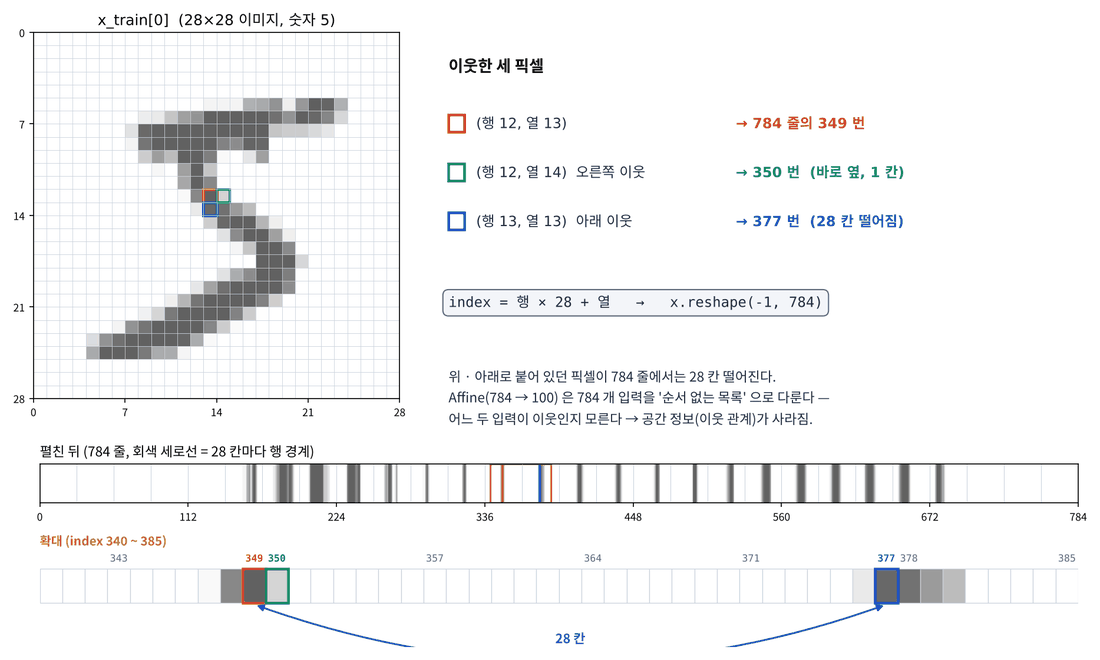

Affine(완전연결, fully connected) 층은 입력을 **길이 784 의 벡터**로 봅니다. 위아래로 붙어 있던 두 픽셀은 펼친 뒤 28칸 떨어지고, Affine 은 784개 입력 각각에 **따로** 가중치를 둡니다 — "어느 픽셀이 어느 픽셀 옆인지"라는 정보를 **구조적으로** 쓰지 않습니다.

**문제 1-1** 그렇다면 픽셀 순서를 **모든 이미지에서 똑같이** 뒤섞어도 MLP 는 똑같이 잘 배울까요? 고정된 순열로 뒤섞은 데이터를 만들고, 원본과 뒤섞은 것으로 같은 MLP (784-100-10, Adam, 1 epoch) 를 학습해 비교하세요. (각 약 5초)

In [ ]:
perm = np.random.default_rng(0).permutation(784)       # 모든 이미지에 같은 순열
X_perm_train = ____
X_perm_test = ____

mlp_acc = {}
for name, A, B in [("original", X_train, X_test), ("permuted", X_perm_train, X_perm_test)]:
    m = mynn.Sequential([mynn.Affine(784, 100, seed=1), mynn.Relu(), mynn.Affine(100, 10, seed=2)])
    mynn.Trainer(m, mynn.Adam(lr=0.001), batch_size=100, seed=0).fit(A, t_train, epochs=1, verbose=False)
    mlp_acc[name] = ____

In [ ]:
print(f"원본 {mlp_acc['original']:.4f}  vs  뒤섞음 {mlp_acc['permuted']:.4f}")
fig, ax = plt.subplots(1, 2, figsize=(5, 2.5))
ax[0].imshow(X_train[0].reshape(28, 28), cmap="gray_r"); ax[0].set_title("original")
ax[1].imshow(X_perm_train[0].reshape(28, 28), cmap="gray_r"); ax[1].set_title("permuted")
for a in ax: a.axis("off")
plt.show()
assert abs(mlp_acc["original"] - mlp_acc["permuted"]) < 0.01; print("✅ 사람은 못 알아보는 그림인데 MLP 정확도는 같다")

In [ ]:
#@title 🔒 정답 보기 1-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTEg4pSA4pSACnBlcm0gPSBucC5yYW5kb20uZGVmYXVsdF9ybmcoMCkucGVybXV0YXRp"
    "b24oNzg0KSAgICAgICAjIOuqqOuToCDsnbTrr7jsp4Dsl5Ag6rCZ7J2AIOyInOyXtApYX3Blcm1fdHJhaW4gPSBY"
    "X3RyYWluWzosIHBlcm1dClhfcGVybV90ZXN0ID0gWF90ZXN0WzosIHBlcm1dCgptbHBfYWNjID0ge30KZm9yIG5h"
    "bWUsIEEsIEIgaW4gWygib3JpZ2luYWwiLCBYX3RyYWluLCBYX3Rlc3QpLCAoInBlcm11dGVkIiwgWF9wZXJtX3Ry"
    "YWluLCBYX3Blcm1fdGVzdCldOgogICAgbSA9IG15bm4uU2VxdWVudGlhbChbbXlubi5BZmZpbmUoNzg0LCAxMDAs"
    "IHNlZWQ9MSksIG15bm4uUmVsdSgpLCBteW5uLkFmZmluZSgxMDAsIDEwLCBzZWVkPTIpXSkKICAgIG15bm4uVHJh"
    "aW5lcihtLCBteW5uLkFkYW0obHI9MC4wMDEpLCBiYXRjaF9zaXplPTEwMCwgc2VlZD0wKS5maXQoQSwgdF90cmFp"
    "biwgZXBvY2hzPTEsIHZlcmJvc2U9RmFsc2UpCiAgICBtbHBfYWNjW25hbWVdID0gbS5hY2N1cmFjeShCLCB0X3Rl"
    "c3Qp"
).decode("utf-8"))

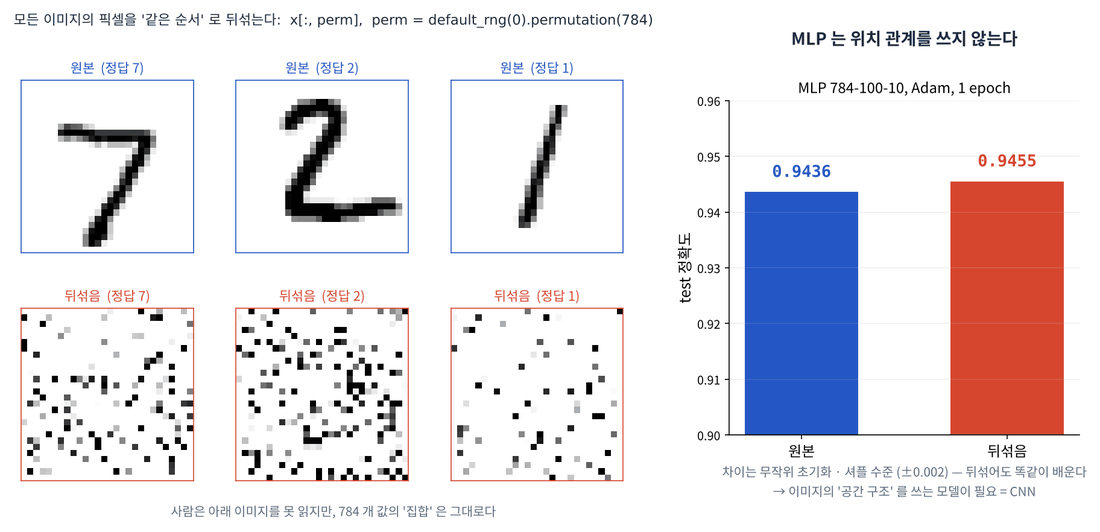

사람에게는 노이즈인 그림으로도 MLP 는 **원본과 같은 정확도**(0.9436 vs 0.9455)를 냅니다. MLP 는 위치 관계를 전혀 쓰지 않으므로, 숫자의 모양에 대한 "상식"을 6만 장에서 **처음부터** 배워야 합니다.

### 파라미터 폭발

**문제 1-2** 완전연결층의 가중치 수와 합성곱 층의 파라미터 수를 계산하는 함수를 만드세요. 합성곱 층은 $F \times F$ 크기 필터 FN 개가 C 개 채널을 모두 덮습니다 (2교시에서 자세히).

In [ ]:
def fc_weights(n_in, n_out):                       # Affine 의 W 개수
    return ____

def conv_params(C, F, FN):                         # 필터 FN 개 × (C·F·F) + 편향 FN 개
    return ____

In [ ]:
rows = [("FC  28×28 → 100", fc_weights(28 * 28, 100)), ("FC  224×224×3 → 1000", fc_weights(224 * 224 * 3, 1000)),
        ("Conv 3×3, RGB → 64", conv_params(3, 3, 64))]
for name, n in rows:
    print(f"{name:22s} {n:>13,}")
assert [n for _, n in rows] == [78_400, 150_528_000, 1_792]; print("✅")

In [ ]:
#@title 🔒 정답 보기 1-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTIg4pSA4pSACmRlZiBmY193ZWlnaHRzKG5faW4sIG5fb3V0KTogICAgICAgICAgICAg"
    "ICAgICAgICAgICMgQWZmaW5lIOydmCBXIOqwnOyImAogICAgcmV0dXJuIG5faW4gKiBuX291dAoKZGVmIGNvbnZf"
    "cGFyYW1zKEMsIEYsIEZOKTogICAgICAgICAgICAgICAgICAgICAgICAgIyDtlYTthLAgRk4g6rCcIMOXIChDwrdG"
    "wrdGKSArIO2OuO2WpSBGTiDqsJwKICAgIHJldHVybiBGTiAqIEMgKiBGICogRiArIEZO"
).decode("utf-8"))

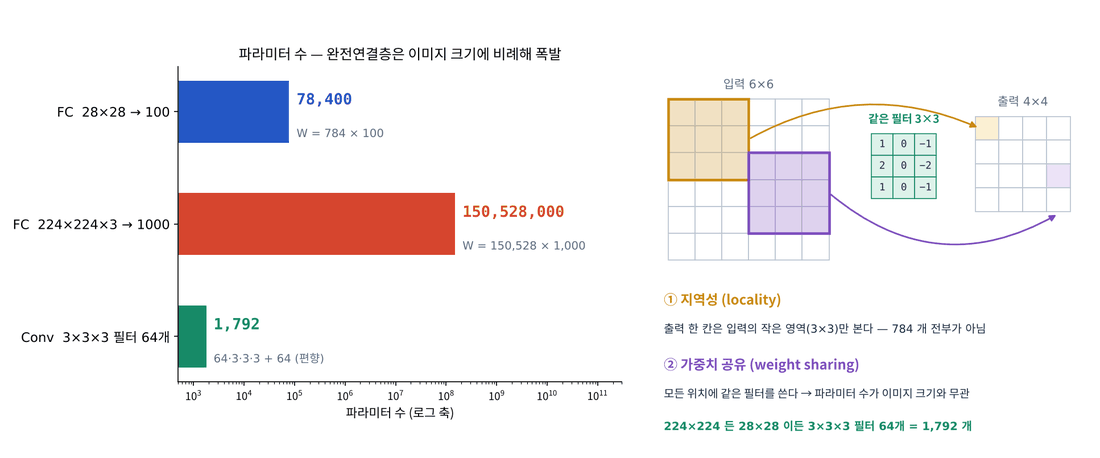

스마트폰 카메라 크기(224×224 컬러)를 완전연결층에 넣으면 첫 층만 **1억 5천만 개** — float32 로 600 MB 입니다. 온디바이스는 불가능합니다. 합성곱은 두 가지 아이디어로 이를 해결합니다.

| 아이디어 | 뜻 | 효과 |
|---|---|---|
| **지역성 (locality)** | 출력 하나는 입력의 **작은 영역**(예: 3×3)만 본다 | 이웃 관계를 구조적으로 사용 |
| **가중치 공유 (weight sharing)** | **같은 필터**를 이미지의 모든 위치에 쓴다 | 파라미터 수가 이미지 크기와 **무관** (1,792개) · 어디에 있든 같은 특징을 검출 |

#### 📌 1교시 정리

- Affine 은 위치 관계를 쓰지 않는다 — 픽셀을 뒤섞어도 정확도가 같다.
- 큰 이미지에서 완전연결층은 파라미터가 폭발한다 (224×224×3 → 1000: 1.5억 개).
- 합성곱 = 지역성 + 가중치 공유.

## 2교시 — 합성곱 연산

**합성곱(convolution)** 은 작은 **필터(커널)** 를 이미지 위에서 미끄러뜨리며, 겹치는 칸끼리 곱해 **모두 더한** 값을 출력에 적는 연산입니다. (수학의 합성곱은 필터를 뒤집지만, 신경망에서는 뒤집지 않는 cross-correlation 을 쓰고 그냥 합성곱이라고 부릅니다 — 필터는 어차피 학습되므로 차이가 없습니다.)

> 🎬 **애니메이션** [D5-2 합성곱 연산](https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/animation.html#d5-2) · [D5-3 다채널 · 다중 필터](https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/animation.html#d5-3)  
> 📝 **워크시트** [2교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/worksheet.html#t2)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

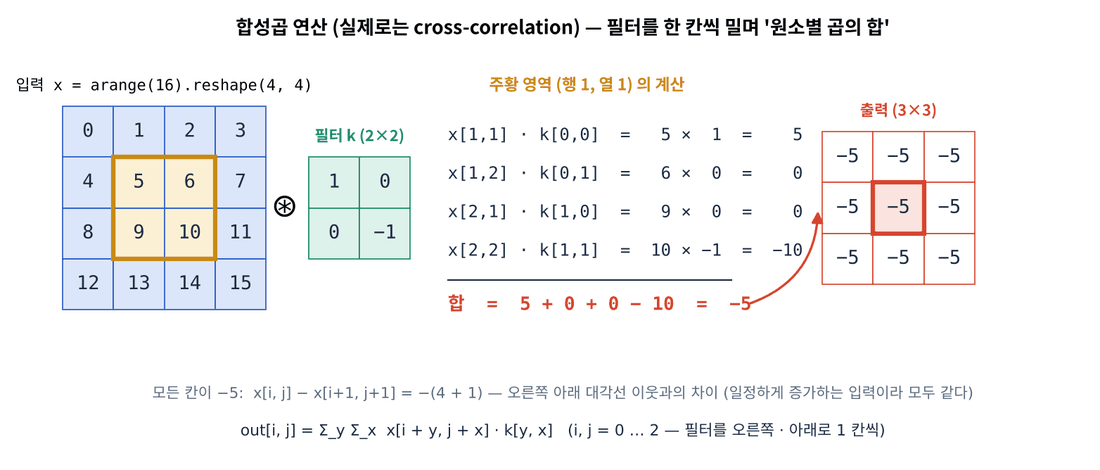

$$\text{out}[i, j] = \sum_{y}\sum_{x} \text{in}[i \cdot S + y,\; j \cdot S + x] \cdot K[y, x] \;(+\, b)$$

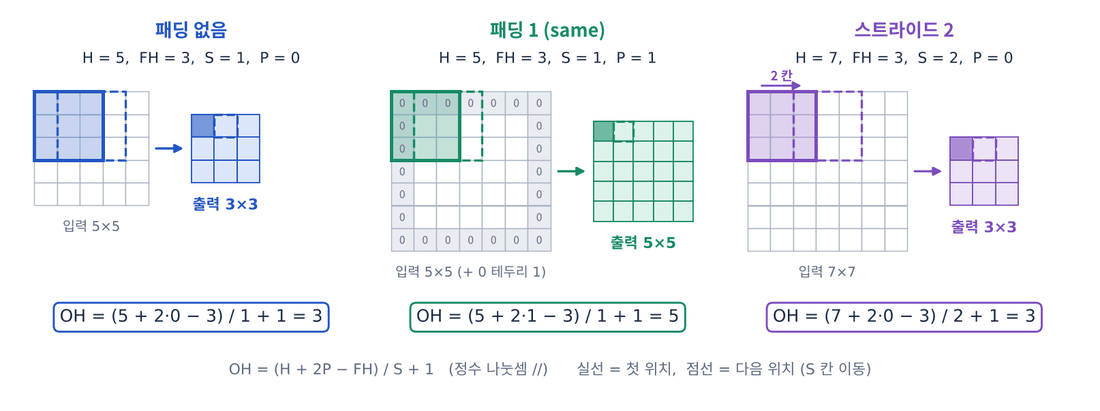

| 용어 | 뜻 |
|---|---|
| **패딩 (padding) P** | 입력 둘레에 0 을 P 줄 덧댐 — 가장자리 정보를 살리고 출력 크기를 유지 |
| **스트라이드 (stride) S** | 필터를 한 번에 S 칸씩 이동 — 출력이 작아짐 |

$$OH = \frac{H + 2P - FH}{S} + 1, \qquad OW = \frac{W + 2P - FW}{S} + 1$$

**문제 2-1** 출력 크기 함수를 만드세요. (나누어떨어지지 않으면 `//` 로 내림)

In [ ]:
def conv_output_size(H, F, S=1, P=0):
    return ____

In [ ]:
cases = [(28, 5, 1, 0, 24), (28, 3, 1, 1, 28), (28, 3, 2, 1, 14), (224, 7, 2, 3, 112), (32, 5, 1, 2, 32), (7, 3, 2, 0, 3)]
for H, F, S, P, ans in cases:
    print(f"H={H:3d} F={F} S={S} P={P} → {conv_output_size(H, F, S, P)}")
    assert conv_output_size(H, F, S, P) == ans
print("✅ (28, 3, 1, 1) → 28: 3×3 필터에 패딩 1 이면 크기가 그대로 (same padding)")

In [ ]:
#@title 🔒 정답 보기 2-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTEg4pSA4pSACmRlZiBjb252X291dHB1dF9zaXplKEgsIEYsIFM9MSwgUD0wKToKICAg"
    "IHJldHVybiAoSCArIDIgKiBQIC0gRikgLy8gUyArIDE="
).decode("utf-8"))

**문제 2-2** 채널 하나 · 필터 하나짜리 합성곱을 이중 for 루프로 구현하세요 (패딩 0, 스트라이드 1).

In [ ]:
def conv2d_single(x, k):
    H, W = x.shape; FH, FW = k.shape
    OH, OW = H - FH + 1, W - FW + 1
    out = np.zeros((OH, OW))
    for i in range(OH):
        for j in range(OW):
            out[i, j] = ____
    return out

In [ ]:
x_ex = np.arange(16, dtype=float).reshape(4, 4)
k_ex = np.array([[1.0, 0.0], [0.0, -1.0]])             # 왼쪽 위 − 오른쪽 아래
print(x_ex, "\n→\n", conv2d_single(x_ex, k_ex))
assert np.array_equal(conv2d_single(x_ex, k_ex), -5 * np.ones((3, 3))); print("✅ 모두 −5: x[i, j] − x[i+1, j+1] = −5")

In [ ]:
#@title 🔒 정답 보기 2-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTIg4pSA4pSACmRlZiBjb252MmRfc2luZ2xlKHgsIGspOgogICAgSCwgVyA9IHguc2hh"
    "cGU7IEZILCBGVyA9IGsuc2hhcGUKICAgIE9ILCBPVyA9IEggLSBGSCArIDEsIFcgLSBGVyArIDEKICAgIG91dCA9"
    "IG5wLnplcm9zKChPSCwgT1cpKQogICAgZm9yIGkgaW4gcmFuZ2UoT0gpOgogICAgICAgIGZvciBqIGluIHJhbmdl"
    "KE9XKToKICAgICAgICAgICAgb3V0W2ksIGpdID0gbnAuc3VtKHhbaTppICsgRkgsIGo6aiArIEZXXSAqIGspCiAg"
    "ICByZXR1cm4gb3V0"
).decode("utf-8"))

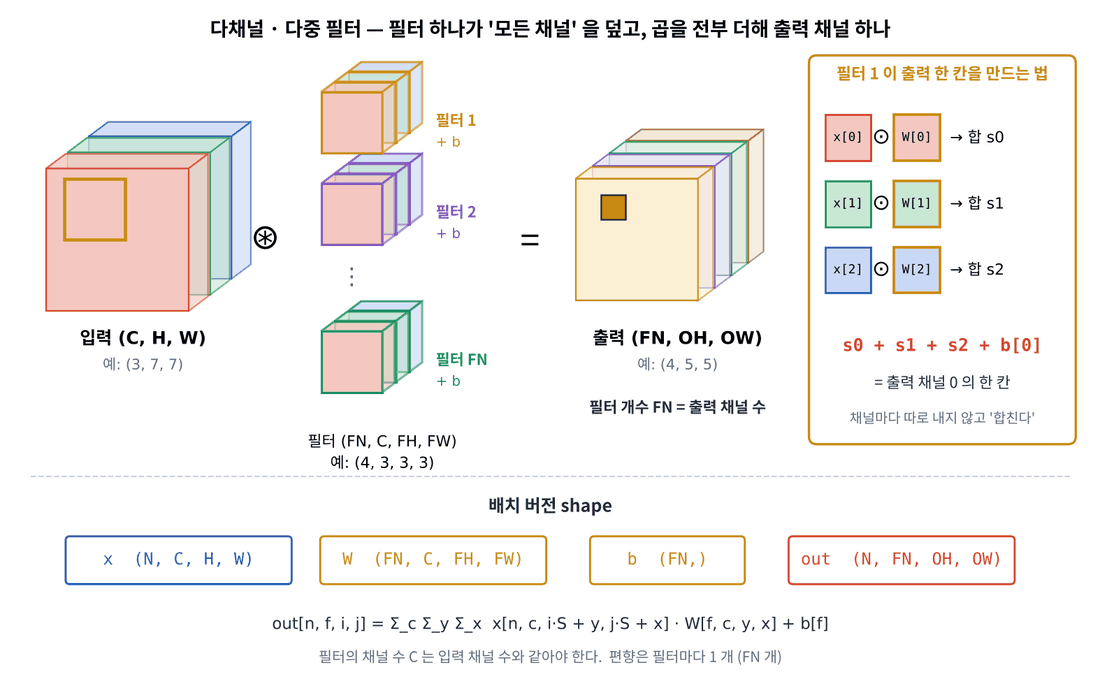

### 다채널 · 다중 필터 · 배치

컬러 이미지는 R, G, B **3 채널**, 중간층 출력은 수십 채널입니다.

- 필터 하나는 입력의 **모든 채널**을 덮는 (C, FH, FW) 블록입니다. 채널마다 곱한 뒤 **모두 더해** 출력 **한 장**이 됩니다.
- 필터를 **FN 개** 쓰면 출력이 FN 장 → 출력 (FN, OH, OW). 필터마다 편향 하나.
- 배치 N 장을 한꺼번에: 입력 **(N, C, H, W)**, 가중치 **(FN, C, FH, FW)**, 출력 **(N, FN, OH, OW)**.

**문제 2-3** 배치 · 다채널 · 다중 필터 · 패딩 · 스트라이드를 모두 지원하는 합성곱을 for 루프로 구현하세요. 패딩은 `np.pad` 로 높이 · 너비 축에만 0 을 덧댑니다.

In [ ]:
def conv_naive(x, W, b, stride=1, pad=0):
    N, C, H, Wd = x.shape
    FN, _, FH, FW = W.shape
    OH, OW = conv_output_size(H, FH, stride, pad), conv_output_size(Wd, FW, stride, pad)
    xp = np.pad(x, [(0, 0), (0, 0), (pad, pad), (pad, pad)])
    out = np.zeros((N, FN, OH, OW))
    for n in range(N):
        for f in range(FN):
            for i in range(OH):
                for j in range(OW):
                    window = ____   # (C, FH, FW)
                    out[n, f, i, j] = ____
    return out

In [ ]:
o = conv_naive(np.ones((1, 2, 3, 3)), np.ones((1, 2, 2, 2)), np.array([1.0]))
assert o.shape == (1, 1, 2, 2) and np.all(o == 9)            # 2채널 × 2×2 = 8 + 편향 1
assert conv_naive(np.ones((2, 3, 7, 7)), np.ones((4, 3, 3, 3)), np.zeros(4), stride=2, pad=1).shape == (2, 4, 4, 4)
print("✅ 채널을 모두 더한다: 2·2·2 + 1 = 9")

In [ ]:
#@title 🔒 정답 보기 2-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTMg4pSA4pSACmRlZiBjb252X25haXZlKHgsIFcsIGIsIHN0cmlkZT0xLCBwYWQ9MCk6"
    "CiAgICBOLCBDLCBILCBXZCA9IHguc2hhcGUKICAgIEZOLCBfLCBGSCwgRlcgPSBXLnNoYXBlCiAgICBPSCwgT1cg"
    "PSBjb252X291dHB1dF9zaXplKEgsIEZILCBzdHJpZGUsIHBhZCksIGNvbnZfb3V0cHV0X3NpemUoV2QsIEZXLCBz"
    "dHJpZGUsIHBhZCkKICAgIHhwID0gbnAucGFkKHgsIFsoMCwgMCksICgwLCAwKSwgKHBhZCwgcGFkKSwgKHBhZCwg"
    "cGFkKV0pCiAgICBvdXQgPSBucC56ZXJvcygoTiwgRk4sIE9ILCBPVykpCiAgICBmb3IgbiBpbiByYW5nZShOKToK"
    "ICAgICAgICBmb3IgZiBpbiByYW5nZShGTik6CiAgICAgICAgICAgIGZvciBpIGluIHJhbmdlKE9IKToKICAgICAg"
    "ICAgICAgICAgIGZvciBqIGluIHJhbmdlKE9XKToKICAgICAgICAgICAgICAgICAgICB3aW5kb3cgPSB4cFtuLCA6"
    "LCBpICogc3RyaWRlOmkgKiBzdHJpZGUgKyBGSCwgaiAqIHN0cmlkZTpqICogc3RyaWRlICsgRlddICAgIyAoQywg"
    "RkgsIEZXKQogICAgICAgICAgICAgICAgICAgIG91dFtuLCBmLCBpLCBqXSA9IG5wLnN1bSh3aW5kb3cgKiBXW2Zd"
    "KSArIGJbZl0KICAgIHJldHVybiBvdXQ="
).decode("utf-8"))

**문제 2-4** 사람이 설계한 필터 — **Sobel 에지 필터** — 를 숫자 5 (`x_train[0]`) 에 적용해 봅니다. 가로 에지 필터는 위가 어둡고 아래가 밝은 곳(가로 경계)에서 크게 반응합니다. 두 필터를 (2, 1, 3, 3) 가중치로 쌓아 한 번에 적용하세요.

In [ ]:
sobel_h = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=float)     # 가로 에지
sobel_v = sobel_h.T                                                         # 세로 에지
W_sobel = ____                    # (2, 1, 3, 3)
edges = conv_naive(X4_train[:1], W_sobel, np.zeros(2), stride=1, pad=1)

In [ ]:
assert W_sobel.shape == (2, 1, 3, 3) and edges.shape == (1, 2, 28, 28)
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
ax[0].imshow(X4_train[0, 0], cmap="gray_r"); ax[0].set_title("input")
for a, e, name in zip(ax[1:], edges[0], ["horizontal edge", "vertical edge"]):
    a.imshow(e, cmap="RdBu"); a.set_title(name)
for a in ax: a.axis("off")
plt.show(); print("✅ 같은 필터가 이미지 전체에서 같은 종류의 경계를 찾는다 (가중치 공유)")

In [ ]:
#@title 🔒 정답 보기 2-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTQg4pSA4pSACnNvYmVsX2ggPSBucC5hcnJheShbWy0xLCAtMiwgLTFdLCBbMCwgMCwg"
    "MF0sIFsxLCAyLCAxXV0sIGR0eXBlPWZsb2F0KSAgICAgIyDqsIDroZwg7JeQ7KeACnNvYmVsX3YgPSBzb2JlbF9o"
    "LlQgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAjIOyEuOuh"
    "nCDsl5Dsp4AKV19zb2JlbCA9IG5wLnN0YWNrKFtzb2JlbF9oLCBzb2JlbF92XSlbOiwgTm9uZSwgOiwgOl0gICAg"
    "ICAgICAgICAgICAgICAgICMgKDIsIDEsIDMsIDMpCmVkZ2VzID0gY29udl9uYWl2ZShYNF90cmFpbls6MV0sIFdf"
    "c29iZWwsIG5wLnplcm9zKDIpLCBzdHJpZGU9MSwgcGFkPTEp"
).decode("utf-8"))

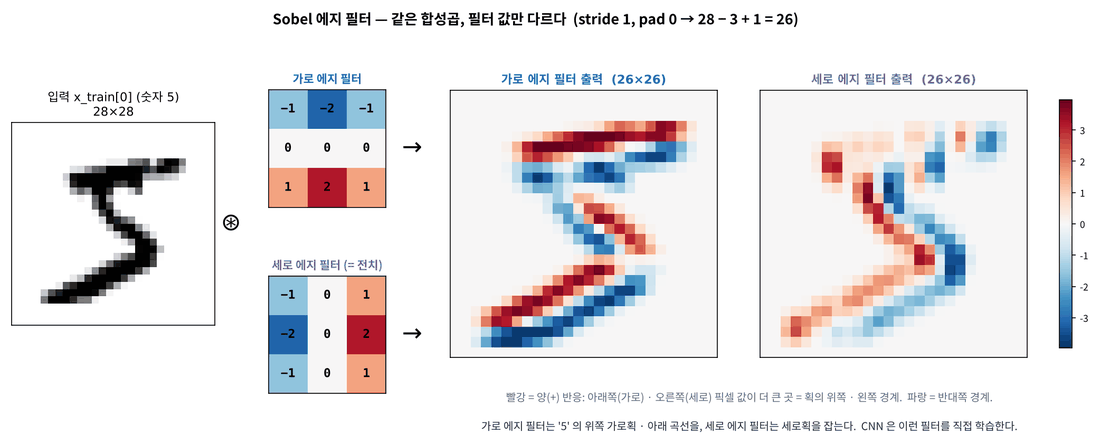

CNN 은 이런 필터를 **사람이 설계하지 않고 데이터로 학습**합니다. 6교시에 학습 전후의 필터를 직접 비교합니다.

#### ⚠️ 자주 하는 실수

- 출력 크기에서 `/` 를 쓰면 실수가 됩니다 — 정수 나눗셈 `//`.
- 다채널 합성곱을 채널마다 따로 출력 — 필터 하나의 결과는 채널을 **모두 더한** 한 장입니다.
- `np.pad` 에 배치 · 채널 축까지 덧대기 — `[(0,0), (0,0), (P,P), (P,P)]`.

#### 📌 2교시 정리

- 합성곱 = 필터를 미끄러뜨리며 원소별 곱의 합. $OH = (H + 2P - FH)/S + 1$.
- 입력 (N, C, H, W), 필터 (FN, C, FH, FW), 출력 (N, FN, OH, OW). 필터 하나 = 출력 채널 하나.
- 패딩은 크기 유지, 스트라이드는 크기 축소.

## 3교시 — im2col: 합성곱을 행렬곱으로

`conv_naive` 는 4중 for 루프라 느립니다. Day 1 에서 배운 것처럼 NumPy 는 **큰 행렬곱 한 번**이 파이썬 루프보다 훨씬 빠릅니다. **im2col** (image to column) 은 필터가 닿는 영역 하나하나를 **행 하나로 펼쳐** 큰 행렬을 만듭니다. 그러면 합성곱이 Day 2 의 `X @ W + b` 가 됩니다.

> 🎬 **애니메이션** [D5-4 im2col](https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/animation.html#d5-4)  
> 📝 **워크시트** [3교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/worksheet.html#t3)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

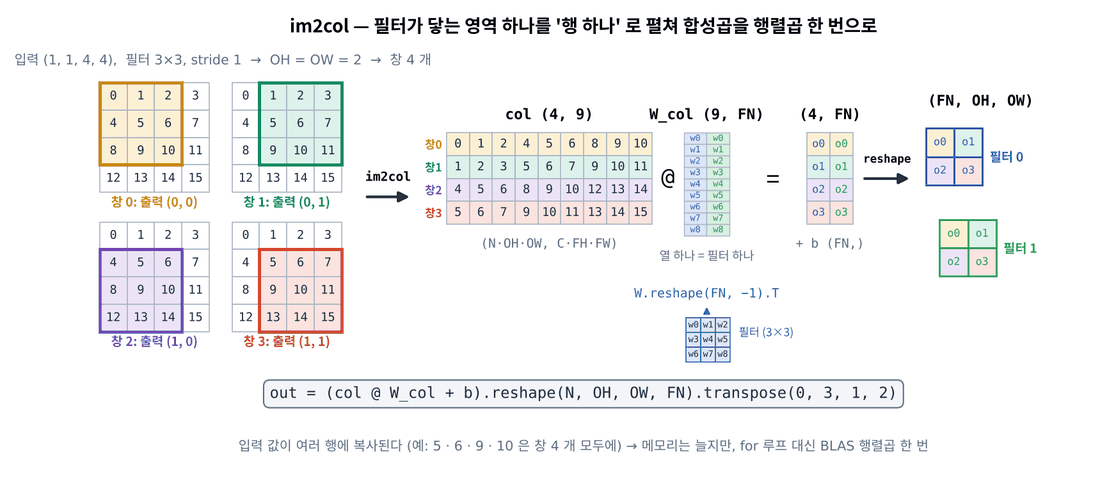

| 단계 | shape |
|---|---|
| 입력 x | (N, C, H, W) |
| **im2col(x)** → col | (N·OH·OW, C·FH·FW) — 영역 하나 = 행 하나 |
| 필터 W.reshape(FN, −1).T → col_W | (C·FH·FW, FN) — 필터 하나 = 열 하나 |
| col @ col_W + b | (N·OH·OW, FN) |
| reshape(N, OH, OW, FN).transpose(0, 3, 1, 2) | (N, FN, OH, OW) |

구현은 영역을 하나씩 도는 대신 **필터 안의 위치 (y, x)** 를 돌며, 그 위치에 해당하는 값을 모든 출력 위치에서 한꺼번에 슬라이싱합니다 (루프 FH·FW 번 = 25번뿐).

**문제 3-1** `im2col` 을 완성하세요.

In [ ]:
def im2col(x, FH, FW, stride=1, pad=0):
    N, C, H, W = x.shape
    OH, OW = conv_output_size(H, FH, stride, pad), conv_output_size(W, FW, stride, pad)
    img = np.pad(x, [(0, 0), (0, 0), (pad, pad), (pad, pad)])
    col = np.zeros((N, C, FH, FW, OH, OW))
    for y in range(FH):
        y_max = y + stride * OH
        for x_ in range(FW):
            x_max = x_ + stride * OW
            col[:, :, y, x_, :, :] = ____
    return col.transpose(0, 4, 5, 1, 2, 3).reshape(____, -1)

In [ ]:
c = im2col(np.arange(16, dtype=float).reshape(1, 1, 4, 4), 3, 3)
print("4×4 입력, 3×3 필터 → col", c.shape, "\n", c)
assert c.shape == (4, 9) and np.array_equal(c[0], [0, 1, 2, 4, 5, 6, 8, 9, 10]); print("✅ 첫 행 = 왼쪽 위 3×3 영역")

In [ ]:
#@title 🔒 정답 보기 3-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTEg4pSA4pSACmRlZiBpbTJjb2woeCwgRkgsIEZXLCBzdHJpZGU9MSwgcGFkPTApOgog"
    "ICAgTiwgQywgSCwgVyA9IHguc2hhcGUKICAgIE9ILCBPVyA9IGNvbnZfb3V0cHV0X3NpemUoSCwgRkgsIHN0cmlk"
    "ZSwgcGFkKSwgY29udl9vdXRwdXRfc2l6ZShXLCBGVywgc3RyaWRlLCBwYWQpCiAgICBpbWcgPSBucC5wYWQoeCwg"
    "WygwLCAwKSwgKDAsIDApLCAocGFkLCBwYWQpLCAocGFkLCBwYWQpXSkKICAgIGNvbCA9IG5wLnplcm9zKChOLCBD"
    "LCBGSCwgRlcsIE9ILCBPVykpCiAgICBmb3IgeSBpbiByYW5nZShGSCk6CiAgICAgICAgeV9tYXggPSB5ICsgc3Ry"
    "aWRlICogT0gKICAgICAgICBmb3IgeF8gaW4gcmFuZ2UoRlcpOgogICAgICAgICAgICB4X21heCA9IHhfICsgc3Ry"
    "aWRlICogT1cKICAgICAgICAgICAgY29sWzosIDosIHksIHhfLCA6LCA6XSA9IGltZ1s6LCA6LCB5OnlfbWF4OnN0"
    "cmlkZSwgeF86eF9tYXg6c3RyaWRlXQogICAgcmV0dXJuIGNvbC50cmFuc3Bvc2UoMCwgNCwgNSwgMSwgMiwgMyku"
    "cmVzaGFwZShOICogT0ggKiBPVywgLTEp"
).decode("utf-8"))

**문제 3-2** im2col 로 합성곱을 만드세요.

In [ ]:
def conv_im2col(x, W, b, stride=1, pad=0):
    FN, C, FH, FW = W.shape
    N, _, H, Wd = x.shape
    OH, OW = conv_output_size(H, FH, stride, pad), conv_output_size(Wd, FW, stride, pad)
    col = im2col(x, FH, FW, stride, pad)                # (N·OH·OW, C·FH·FW)
    col_W = ____                       # (C·FH·FW, FN)
    out = ____                             # (N·OH·OW, FN)
    return out.reshape(N, OH, OW, FN).transpose(____)

In [ ]:
rng3 = np.random.default_rng(3)
xr, Wr, br = rng3.normal(size=(2, 3, 7, 7)), rng3.normal(size=(4, 3, 3, 3)), rng3.normal(size=4)
for S, P in [(1, 0), (1, 1), (2, 1)]:
    assert np.allclose(conv_im2col(xr, Wr, br, S, P), conv_naive(xr, Wr, br, S, P))
print("✅ 루프 버전과 결과가 같다 (stride · pad 3가지)")

In [ ]:
#@title 🔒 정답 보기 3-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTIg4pSA4pSACmRlZiBjb252X2ltMmNvbCh4LCBXLCBiLCBzdHJpZGU9MSwgcGFkPTAp"
    "OgogICAgRk4sIEMsIEZILCBGVyA9IFcuc2hhcGUKICAgIE4sIF8sIEgsIFdkID0geC5zaGFwZQogICAgT0gsIE9X"
    "ID0gY29udl9vdXRwdXRfc2l6ZShILCBGSCwgc3RyaWRlLCBwYWQpLCBjb252X291dHB1dF9zaXplKFdkLCBGVywg"
    "c3RyaWRlLCBwYWQpCiAgICBjb2wgPSBpbTJjb2woeCwgRkgsIEZXLCBzdHJpZGUsIHBhZCkgICAgICAgICAgICAg"
    "ICAgIyAoTsK3T0jCt09XLCBDwrdGSMK3RlcpCiAgICBjb2xfVyA9IFcucmVzaGFwZShGTiwgLTEpLlQgICAgICAg"
    "ICAgICAgICAgICAgICAgICMgKEPCt0ZIwrdGVywgRk4pCiAgICBvdXQgPSBjb2wgQCBjb2xfVyArIGIgICAgICAg"
    "ICAgICAgICAgICAgICAgICAgICAgICMgKE7Ct09IwrdPVywgRk4pCiAgICByZXR1cm4gb3V0LnJlc2hhcGUoTiwg"
    "T0gsIE9XLCBGTikudHJhbnNwb3NlKDAsIDMsIDEsIDIp"
).decode("utf-8"))

**문제 3-3** MNIST 20장, 5×5 필터 30개로 두 방법의 시간과 im2col 의 메모리를 비교하세요.

In [ ]:
W30 = 0.1 * np.random.default_rng(0).standard_normal((30, 1, 5, 5)); b30 = np.zeros(30)
xb = X4_train[:20]
t0 = time.perf_counter(); o_naive = conv_naive(xb, W30, b30); t_naive = time.perf_counter() - t0
t0 = time.perf_counter()
for _ in range(10):
    o_fast = conv_im2col(xb, W30, b30)
t_fast = (time.perf_counter() - t0) / 10
col_ratio = ____

In [ ]:
print(f"for 루프 {t_naive:.2f} 초  vs  im2col {t_fast * 1000:.1f} ms  → 약 {t_naive / t_fast:.0f} 배")
print(f"메모리: 입력 100장 {X4_train[:100].size:,} 값 → col {im2col(X4_train[:100], 5, 5).shape} = {col_ratio:.1f} 배")
assert np.allclose(o_naive, o_fast) and t_naive / t_fast > 20 and abs(col_ratio - 18.37) < 0.01; print("✅")

In [ ]:
#@title 🔒 정답 보기 3-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTMg4pSA4pSAClczMCA9IDAuMSAqIG5wLnJhbmRvbS5kZWZhdWx0X3JuZygwKS5zdGFu"
    "ZGFyZF9ub3JtYWwoKDMwLCAxLCA1LCA1KSk7IGIzMCA9IG5wLnplcm9zKDMwKQp4YiA9IFg0X3RyYWluWzoyMF0K"
    "dDAgPSB0aW1lLnBlcmZfY291bnRlcigpOyBvX25haXZlID0gY29udl9uYWl2ZSh4YiwgVzMwLCBiMzApOyB0X25h"
    "aXZlID0gdGltZS5wZXJmX2NvdW50ZXIoKSAtIHQwCnQwID0gdGltZS5wZXJmX2NvdW50ZXIoKQpmb3IgXyBpbiBy"
    "YW5nZSgxMCk6CiAgICBvX2Zhc3QgPSBjb252X2ltMmNvbCh4YiwgVzMwLCBiMzApCnRfZmFzdCA9ICh0aW1lLnBl"
    "cmZfY291bnRlcigpIC0gdDApIC8gMTAKY29sX3JhdGlvID0gaW0yY29sKFg0X3RyYWluWzoxMDBdLCA1LCA1KS5z"
    "aXplIC8gWDRfdHJhaW5bOjEwMF0uc2l6ZQ=="
).decode("utf-8"))

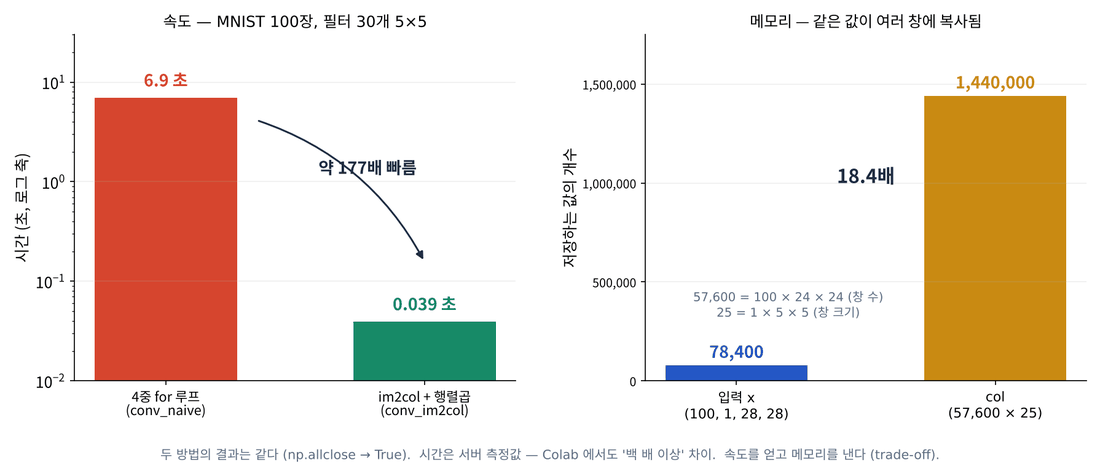

**속도와 메모리의 교환(trade-off)** — im2col 은 겹치는 영역을 중복해서 복사하므로 메모리를 약 $FH \cdot FW / S^2$ 배 (여기서는 25 × 24²/28² ≈ 18.4배) 더 쓰는 대신, 계산을 **행렬곱 한 번**으로 바꿔 백 배 이상 빨라집니다. 행렬곱은 CPU · GPU · NPU 가 가장 잘하는 연산이라, 실제 딥러닝 라이브러리도 비슷한 방법을 씁니다. 메모리가 빠듯한 온디바이스 환경에서는 이 교환 비율이 중요한 설계 기준이 됩니다.

#### 📌 3교시 정리

- im2col: (N, C, H, W) → (N·OH·OW, C·FH·FW). 필터는 (C·FH·FW, FN) 으로.
- 합성곱 = `col @ col_W + b` → reshape · transpose. **Affine 과 같은 행렬곱**.
- 속도 ↑↑, 메모리 ↑ (영역이 겹친 만큼 중복).

## 4교시 — Convolution · Pooling 계층 → `mynn.py`

이제 합성곱을 Day 4 `mynn` 규약(`params`, `grads`, `forward(x, train_flg)`, `backward(dout)`)을 따르는 **계층**으로 만들어 `mynn.py` 에 추가합니다.

> 🎬 **애니메이션** [D5-5 Max Pooling](https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/animation.html#d5-5)  
> 📝 **워크시트** [4교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/worksheet.html#t4)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

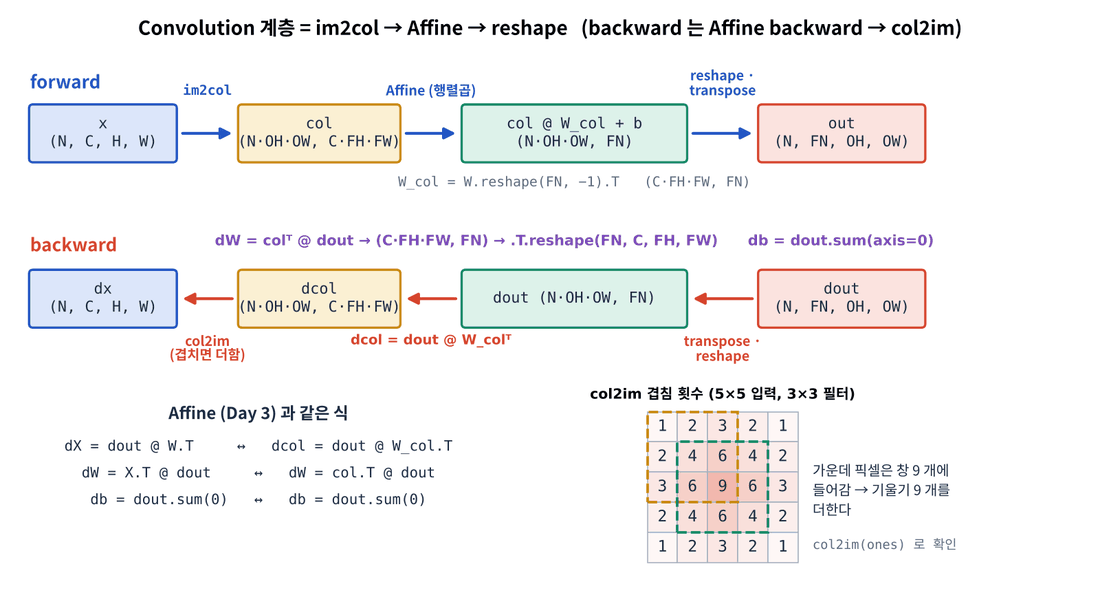

### Convolution 의 역전파 — Affine 그대로

forward 는 `col @ col_W + b` — Day 3 Affine 의 `X @ W + b` 와 **같은 식**입니다 (X 자리에 col, W 자리에 col_W). 그래서 backward 도 Affine 그대로입니다.

| Affine (Day 3) | Convolution |
|---|---|
| `dW = X.T @ dout` | `dW = (col.T @ dout).T.reshape(FN, C, FH, FW)` |
| `db = dout.sum(axis=0)` | `db = dout.sum(axis=0)` (dout 을 (N·OH·OW, FN) 으로 펼친 뒤) |
| `dX = dout @ W.T` | `dcol = dout @ col_W.T` → **col2im** → dx (N, C, H, W) |

**col2im** 은 im2col 의 반대입니다. 한 입력 픽셀은 여러 영역(여러 col 행)에 복사되어 쓰였으므로, 기울기는 그 자리들에서 온 것을 **모두 더합니다** — Day 3 "덧셈 노드의 역(복사 노드)은 기울기를 더한다" 와 같은 원리입니다.

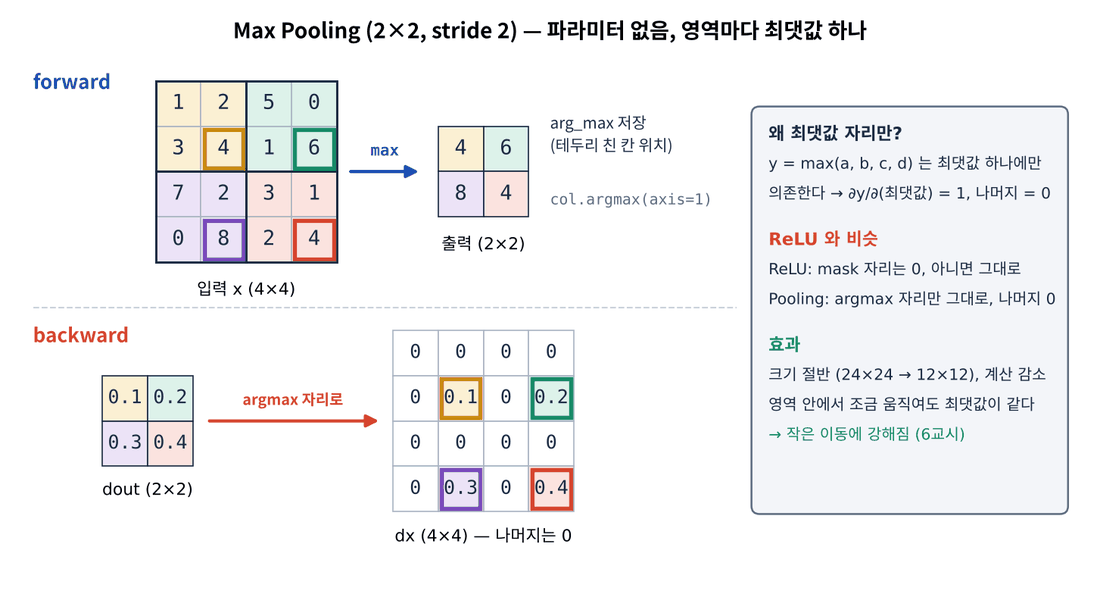

### Max Pooling

2×2 영역에서 **최댓값**만 남겨 크기를 절반으로 줄입니다 (stride 2). 학습할 파라미터가 **없고**, 채널 수는 그대로입니다. 영역 안에서 조금 움직여도 최댓값은 그대로인 경우가 많아 **작은 이동에 둔감**해집니다. 역전파는 ReLU 의 mask 처럼, 순전파 때 최댓값이었던 자리(`arg_max`)로만 dout 을 보내고 나머지는 0 입니다.

**문제 4-1 ~ 4-3** 아래 셀이 Day 5 부분 코드를 **`mynn_conv.py`** 파일로 씁니다 (`%%writefile`). 빈칸을 채워 `Convolution` 과 `Pooling` 을 완성하세요. `im2col` 은 3교시와 같고, `col2im` 은 주어집니다.

In [ ]:
%%writefile mynn_conv.py
# ═════════════ Day 5 — 합성곱 신경망 (CNN) ═════════════
def conv_output_size(input_size, filter_size, stride=1, pad=0):
    return (input_size + 2 * pad - filter_size) // stride + 1


def im2col(x, FH, FW, stride=1, pad=0):
    """(N, C, H, W) → (N·OH·OW, C·FH·FW): 필터가 닿는 영역 하나를 행 하나로 펼친다"""
    N, C, H, W = x.shape
    OH, OW = conv_output_size(H, FH, stride, pad), conv_output_size(W, FW, stride, pad)
    img = np.pad(x, [(0, 0), (0, 0), (pad, pad), (pad, pad)])
    col = np.zeros((N, C, FH, FW, OH, OW))
    for y in range(FH):
        y_max = y + stride * OH
        for x_ in range(FW):
            x_max = x_ + stride * OW
            col[:, :, y, x_, :, :] = img[:, :, y:y_max:stride, x_:x_max:stride]
    return col.transpose(0, 4, 5, 1, 2, 3).reshape(N * OH * OW, -1)


def col2im(col, input_shape, FH, FW, stride=1, pad=0):
    """im2col 의 반대 — 겹치는 자리는 더한다 (역전파용)"""
    N, C, H, W = input_shape
    OH, OW = conv_output_size(H, FH, stride, pad), conv_output_size(W, FW, stride, pad)
    col = col.reshape(N, OH, OW, C, FH, FW).transpose(0, 3, 4, 5, 1, 2)
    img = np.zeros((N, C, H + 2 * pad + stride - 1, W + 2 * pad + stride - 1))
    for y in range(FH):
        y_max = y + stride * OH
        for x_ in range(FW):
            x_max = x_ + stride * OW
            img[:, :, y:y_max:stride, x_:x_max:stride] += col[:, :, y, x_, :, :]
    return img[:, :, pad:H + pad, pad:W + pad]


class Convolution(Layer):
    def __init__(self, in_channels, out_channels, filter_size, stride=1, pad=0, weight_init="he", seed=0):
        super().__init__()
        rng = np.random.default_rng(seed)
        n_in = in_channels * filter_size * filter_size
        self.params["W"] = init_std(weight_init, n_in) * rng.standard_normal((out_channels, in_channels, filter_size, filter_size))
        self.params["b"] = np.zeros(out_channels)
        self.stride, self.pad = stride, pad

    def forward(self, x, train_flg=True):
        FN, C, FH, FW = self.params["W"].shape
        N, _, H, W = x.shape
        OH, OW = conv_output_size(H, FH, self.stride, self.pad), conv_output_size(W, FW, self.stride, self.pad)
        self.x_shape = x.shape
        self.col = ____          # (N·OH·OW, C·FH·FW)
        self.col_W = self.params["W"].reshape(FN, -1).T               # (C·FH·FW, FN)
        out = ____                # (N·OH·OW, FN) — Affine 과 같은 행렬곱
        return out.reshape(N, OH, OW, FN).transpose(0, 3, 1, 2)      # (N, FN, OH, OW)

    def backward(self, dout):
        FN, C, FH, FW = self.params["W"].shape
        dout = dout.transpose(0, 2, 3, 1).reshape(-1, FN)            # (N·OH·OW, FN)
        self.grads["b"] = dout.sum(axis=0)
        self.grads["W"] = ____.reshape(FN, C, FH, FW)
        dcol = ____                                    # Affine 의 dX 와 같은 식
        return ____


class Pooling(Layer):
    """Max Pooling"""
    def __init__(self, pool_h, pool_w, stride=None, pad=0):
        super().__init__()
        self.pool_h, self.pool_w, self.pad = pool_h, pool_w, pad
        self.stride = stride or pool_h

    def forward(self, x, train_flg=True):
        N, C, H, W = x.shape
        OH = conv_output_size(H, self.pool_h, self.stride, self.pad)
        OW = conv_output_size(W, self.pool_w, self.stride, self.pad)
        self.x_shape = x.shape
        col = im2col(x, self.pool_h, self.pool_w, self.stride, self.pad).reshape(-1, self.pool_h * self.pool_w)
        self.arg_max = ____                             # 역전파 때 기울기를 보낼 자리
        out = col[np.arange(col.shape[0]), self.arg_max]              # = col.max(axis=1)
        return out.reshape(N, OH, OW, C).transpose(0, 3, 1, 2)

    def backward(self, dout):
        dout = dout.transpose(0, 2, 3, 1)
        pool_size = self.pool_h * self.pool_w
        dmax = np.zeros((dout.size, pool_size))
        dmax[np.arange(self.arg_max.size), ____] = dout.ravel()   # 최댓값 자리에만
        dcol = dmax.reshape(dout.shape[0] * dout.shape[1] * dout.shape[2], -1)
        return col2im(dcol, self.x_shape, self.pool_h, self.pool_w, self.stride, self.pad)

In [ ]:
#@title 🔒 정답 보기 4-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTEg4pSA4pSACiUld3JpdGVmaWxlIG15bm5fY29udi5weQojIOKVkOKVkOKVkOKVkOKV"
    "kOKVkOKVkOKVkOKVkOKVkOKVkOKVkOKVkCBEYXkgNSDigJQg7ZWp7ISx6rOxIOyLoOqyveunnSAoQ05OKSDilZDi"
    "lZDilZDilZDilZDilZDilZDilZDilZDilZDilZDilZDilZAKZGVmIGNvbnZfb3V0cHV0X3NpemUoaW5wdXRfc2l6"
    "ZSwgZmlsdGVyX3NpemUsIHN0cmlkZT0xLCBwYWQ9MCk6CiAgICByZXR1cm4gKGlucHV0X3NpemUgKyAyICogcGFk"
    "IC0gZmlsdGVyX3NpemUpIC8vIHN0cmlkZSArIDEKCgpkZWYgaW0yY29sKHgsIEZILCBGVywgc3RyaWRlPTEsIHBh"
    "ZD0wKToKICAgICIiIihOLCBDLCBILCBXKSDihpIgKE7Ct09IwrdPVywgQ8K3RkjCt0ZXKTog7ZWE7YSw6rCAIOuL"
    "v+uKlCDsmIHsl60g7ZWY64KY66W8IO2WiSDtlZjrgpjroZwg7Y687Lmc64ukIiIiCiAgICBOLCBDLCBILCBXID0g"
    "eC5zaGFwZQogICAgT0gsIE9XID0gY29udl9vdXRwdXRfc2l6ZShILCBGSCwgc3RyaWRlLCBwYWQpLCBjb252X291"
    "dHB1dF9zaXplKFcsIEZXLCBzdHJpZGUsIHBhZCkKICAgIGltZyA9IG5wLnBhZCh4LCBbKDAsIDApLCAoMCwgMCks"
    "IChwYWQsIHBhZCksIChwYWQsIHBhZCldKQogICAgY29sID0gbnAuemVyb3MoKE4sIEMsIEZILCBGVywgT0gsIE9X"
    "KSkKICAgIGZvciB5IGluIHJhbmdlKEZIKToKICAgICAgICB5X21heCA9IHkgKyBzdHJpZGUgKiBPSAogICAgICAg"
    "IGZvciB4XyBpbiByYW5nZShGVyk6CiAgICAgICAgICAgIHhfbWF4ID0geF8gKyBzdHJpZGUgKiBPVwogICAgICAg"
    "ICAgICBjb2xbOiwgOiwgeSwgeF8sIDosIDpdID0gaW1nWzosIDosIHk6eV9tYXg6c3RyaWRlLCB4Xzp4X21heDpz"
    "dHJpZGVdCiAgICByZXR1cm4gY29sLnRyYW5zcG9zZSgwLCA0LCA1LCAxLCAyLCAzKS5yZXNoYXBlKE4gKiBPSCAq"
    "IE9XLCAtMSkKCgpkZWYgY29sMmltKGNvbCwgaW5wdXRfc2hhcGUsIEZILCBGVywgc3RyaWRlPTEsIHBhZD0wKToK"
    "ICAgICIiImltMmNvbCDsnZgg67CY64yAIOKAlCDqsrnsuZjripQg7J6Q66as64qUIOuNlO2VnOuLpCAo7Jet7KCE"
    "7YyM7JqpKSIiIgogICAgTiwgQywgSCwgVyA9IGlucHV0X3NoYXBlCiAgICBPSCwgT1cgPSBjb252X291dHB1dF9z"
    "aXplKEgsIEZILCBzdHJpZGUsIHBhZCksIGNvbnZfb3V0cHV0X3NpemUoVywgRlcsIHN0cmlkZSwgcGFkKQogICAg"
    "Y29sID0gY29sLnJlc2hhcGUoTiwgT0gsIE9XLCBDLCBGSCwgRlcpLnRyYW5zcG9zZSgwLCAzLCA0LCA1LCAxLCAy"
    "KQogICAgaW1nID0gbnAuemVyb3MoKE4sIEMsIEggKyAyICogcGFkICsgc3RyaWRlIC0gMSwgVyArIDIgKiBwYWQg"
    "KyBzdHJpZGUgLSAxKSkKICAgIGZvciB5IGluIHJhbmdlKEZIKToKICAgICAgICB5X21heCA9IHkgKyBzdHJpZGUg"
    "KiBPSAogICAgICAgIGZvciB4XyBpbiByYW5nZShGVyk6CiAgICAgICAgICAgIHhfbWF4ID0geF8gKyBzdHJpZGUg"
    "KiBPVwogICAgICAgICAgICBpbWdbOiwgOiwgeTp5X21heDpzdHJpZGUsIHhfOnhfbWF4OnN0cmlkZV0gKz0gY29s"
    "WzosIDosIHksIHhfLCA6LCA6XQogICAgcmV0dXJuIGltZ1s6LCA6LCBwYWQ6SCArIHBhZCwgcGFkOlcgKyBwYWRd"
    "CgoKY2xhc3MgQ29udm9sdXRpb24oTGF5ZXIpOgogICAgZGVmIF9faW5pdF9fKHNlbGYsIGluX2NoYW5uZWxzLCBv"
    "dXRfY2hhbm5lbHMsIGZpbHRlcl9zaXplLCBzdHJpZGU9MSwgcGFkPTAsIHdlaWdodF9pbml0PSJoZSIsIHNlZWQ9"
    "MCk6CiAgICAgICAgc3VwZXIoKS5fX2luaXRfXygpCiAgICAgICAgcm5nID0gbnAucmFuZG9tLmRlZmF1bHRfcm5n"
    "KHNlZWQpCiAgICAgICAgbl9pbiA9IGluX2NoYW5uZWxzICogZmlsdGVyX3NpemUgKiBmaWx0ZXJfc2l6ZQogICAg"
    "ICAgIHNlbGYucGFyYW1zWyJXIl0gPSBpbml0X3N0ZCh3ZWlnaHRfaW5pdCwgbl9pbikgKiBybmcuc3RhbmRhcmRf"
    "bm9ybWFsKChvdXRfY2hhbm5lbHMsIGluX2NoYW5uZWxzLCBmaWx0ZXJfc2l6ZSwgZmlsdGVyX3NpemUpKQogICAg"
    "ICAgIHNlbGYucGFyYW1zWyJiIl0gPSBucC56ZXJvcyhvdXRfY2hhbm5lbHMpCiAgICAgICAgc2VsZi5zdHJpZGUs"
    "IHNlbGYucGFkID0gc3RyaWRlLCBwYWQKCiAgICBkZWYgZm9yd2FyZChzZWxmLCB4LCB0cmFpbl9mbGc9VHJ1ZSk6"
    "CiAgICAgICAgRk4sIEMsIEZILCBGVyA9IHNlbGYucGFyYW1zWyJXIl0uc2hhcGUKICAgICAgICBOLCBfLCBILCBX"
    "ID0geC5zaGFwZQogICAgICAgIE9ILCBPVyA9IGNvbnZfb3V0cHV0X3NpemUoSCwgRkgsIHNlbGYuc3RyaWRlLCBz"
    "ZWxmLnBhZCksIGNvbnZfb3V0cHV0X3NpemUoVywgRlcsIHNlbGYuc3RyaWRlLCBzZWxmLnBhZCkKICAgICAgICBz"
    "ZWxmLnhfc2hhcGUgPSB4LnNoYXBlCiAgICAgICAgc2VsZi5jb2wgPSBpbTJjb2woeCwgRkgsIEZXLCBzZWxmLnN0"
    "cmlkZSwgc2VsZi5wYWQpICAgICAgICAgICMgKE7Ct09IwrdPVywgQ8K3RkjCt0ZXKQogICAgICAgIHNlbGYuY29s"
    "X1cgPSBzZWxmLnBhcmFtc1siVyJdLnJlc2hhcGUoRk4sIC0xKS5UICAgICAgICAgICAgICAgIyAoQ8K3RkjCt0ZX"
    "LCBGTikKICAgICAgICBvdXQgPSBzZWxmLmNvbCBAIHNlbGYuY29sX1cgKyBzZWxmLnBhcmFtc1siYiJdICAgICAg"
    "ICAgICAgICAgICMgKE7Ct09IwrdPVywgRk4pIOKAlCBBZmZpbmUg6rO8IOqwmeydgCDtlonroKzqs7EKICAgICAg"
    "ICByZXR1cm4gb3V0LnJlc2hhcGUoTiwgT0gsIE9XLCBGTikudHJhbnNwb3NlKDAsIDMsIDEsIDIpICAgICAgIyAo"
    "TiwgRk4sIE9ILCBPVykKCiAgICBkZWYgYmFja3dhcmQoc2VsZiwgZG91dCk6CiAgICAgICAgRk4sIEMsIEZILCBG"
    "VyA9IHNlbGYucGFyYW1zWyJXIl0uc2hhcGUKICAgICAgICBkb3V0ID0gZG91dC50cmFuc3Bvc2UoMCwgMiwgMywg"
    "MSkucmVzaGFwZSgtMSwgRk4pICAgICAgICAgICAgIyAoTsK3T0jCt09XLCBGTikKICAgICAgICBzZWxmLmdyYWRz"
    "WyJiIl0gPSBkb3V0LnN1bShheGlzPTApCiAgICAgICAgc2VsZi5ncmFkc1siVyJdID0gKHNlbGYuY29sLlQgQCBk"
    "b3V0KS5ULnJlc2hhcGUoRk4sIEMsIEZILCBGVykKICAgICAgICBkY29sID0gZG91dCBAIHNlbGYuY29sX1cuVCAg"
    "ICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICMgQWZmaW5lIOydmCBkWCDsmYAg6rCZ7J2AIOyLnQog"
    "ICAgICAgIHJldHVybiBjb2wyaW0oZGNvbCwgc2VsZi54X3NoYXBlLCBGSCwgRlcsIHNlbGYuc3RyaWRlLCBzZWxm"
    "LnBhZCkKCgpjbGFzcyBQb29saW5nKExheWVyKToKICAgICIiIk1heCBQb29saW5nIiIiCiAgICBkZWYgX19pbml0"
    "X18oc2VsZiwgcG9vbF9oLCBwb29sX3csIHN0cmlkZT1Ob25lLCBwYWQ9MCk6CiAgICAgICAgc3VwZXIoKS5fX2lu"
    "aXRfXygpCiAgICAgICAgc2VsZi5wb29sX2gsIHNlbGYucG9vbF93LCBzZWxmLnBhZCA9IHBvb2xfaCwgcG9vbF93"
    "LCBwYWQKICAgICAgICBzZWxmLnN0cmlkZSA9IHN0cmlkZSBvciBwb29sX2gKCiAgICBkZWYgZm9yd2FyZChzZWxm"
    "LCB4LCB0cmFpbl9mbGc9VHJ1ZSk6CiAgICAgICAgTiwgQywgSCwgVyA9IHguc2hhcGUKICAgICAgICBPSCA9IGNv"
    "bnZfb3V0cHV0X3NpemUoSCwgc2VsZi5wb29sX2gsIHNlbGYuc3RyaWRlLCBzZWxmLnBhZCkKICAgICAgICBPVyA9"
    "IGNvbnZfb3V0cHV0X3NpemUoVywgc2VsZi5wb29sX3csIHNlbGYuc3RyaWRlLCBzZWxmLnBhZCkKICAgICAgICBz"
    "ZWxmLnhfc2hhcGUgPSB4LnNoYXBlCiAgICAgICAgY29sID0gaW0yY29sKHgsIHNlbGYucG9vbF9oLCBzZWxmLnBv"
    "b2xfdywgc2VsZi5zdHJpZGUsIHNlbGYucGFkKS5yZXNoYXBlKC0xLCBzZWxmLnBvb2xfaCAqIHNlbGYucG9vbF93"
    "KQogICAgICAgIHNlbGYuYXJnX21heCA9IGNvbC5hcmdtYXgoYXhpcz0xKSAgICAgICAgICAgICAgICAgICAgICAg"
    "ICAgICAgIyDsl63soITtjIwg65WMIOq4sOyauOq4sOulvCDrs7Trgrwg7J6Q66asCiAgICAgICAgb3V0ID0gY29s"
    "W25wLmFyYW5nZShjb2wuc2hhcGVbMF0pLCBzZWxmLmFyZ19tYXhdICAgICAgICAgICAgICAjID0gY29sLm1heChh"
    "eGlzPTEpCiAgICAgICAgcmV0dXJuIG91dC5yZXNoYXBlKE4sIE9ILCBPVywgQykudHJhbnNwb3NlKDAsIDMsIDEs"
    "IDIpCgogICAgZGVmIGJhY2t3YXJkKHNlbGYsIGRvdXQpOgogICAgICAgIGRvdXQgPSBkb3V0LnRyYW5zcG9zZSgw"
    "LCAyLCAzLCAxKQogICAgICAgIHBvb2xfc2l6ZSA9IHNlbGYucG9vbF9oICogc2VsZi5wb29sX3cKICAgICAgICBk"
    "bWF4ID0gbnAuemVyb3MoKGRvdXQuc2l6ZSwgcG9vbF9zaXplKSkKICAgICAgICBkbWF4W25wLmFyYW5nZShzZWxm"
    "LmFyZ19tYXguc2l6ZSksIHNlbGYuYXJnX21heF0gPSBkb3V0LnJhdmVsKCkgICAjIOy1nOuMk+qwkiDsnpDrpqzs"
    "l5Drp4wKICAgICAgICBkY29sID0gZG1heC5yZXNoYXBlKGRvdXQuc2hhcGVbMF0gKiBkb3V0LnNoYXBlWzFdICog"
    "ZG91dC5zaGFwZVsyXSwgLTEpCiAgICAgICAgcmV0dXJuIGNvbDJpbShkY29sLCBzZWxmLnhfc2hhcGUsIHNlbGYu"
    "cG9vbF9oLCBzZWxmLnBvb2xfdywgc2VsZi5zdHJpZGUsIHNlbGYucGFkKQ=="
).decode("utf-8"))

아래 셀이 `mynn.py` = (Day 4 의 `mynn_day4.py`) + (`mynn_conv.py`) 를 만들고 다시 import 합니다. `mynn_conv.py` 를 고쳤다면 이 셀도 다시 실행하세요.

In [ ]:
day4_code = open("mynn_day4.py", encoding="utf-8").read().split(DAY5_MARK)[0].rstrip() + "\n\n\n"
day5_code = open("mynn_conv.py", encoding="utf-8").read()
open("mynn.py", "w", encoding="utf-8").write(day4_code + day5_code)
import mynn
importlib.reload(mynn)
print("mynn.py", os.path.getsize("mynn.py"), "bytes · CNN 계층:", [n for n in ("im2col", "col2im", "Convolution", "Pooling") if hasattr(mynn, n)])

**문제 4-4** Day 3 방식의 gradient check 로 두 계층을 확인하세요 — $L = \sum(\text{forward}(x) \odot \text{dout})$ 의 수치 미분과 비교합니다. 패딩 · 스트라이드가 다른 Convolution 두 개와 Pooling 하나를 검사합니다.

In [ ]:
def layer_check(layer, x, rng_):
    out = layer.forward(x)
    dout = rng_.normal(size=out.shape)
    f = lambda _: np.sum(layer.forward(x) * dout)
    errs = {"dx": mynn.rel_error(layer.backward(dout), ____)}
    layer.forward(x); layer.backward(dout)                        # 수치 미분이 저장값을 바꿨으므로 다시
    for k, p in layer.params.items():
        errs[k] = mynn.rel_error(layer.grads[k], mynn.numerical_gradient(f, p))
    return errs

rng4 = np.random.default_rng(0)
x4 = rng4.normal(size=(2, 3, 7, 7))
checks = {"conv s1 p1": layer_check(mynn.Convolution(3, 4, 3, stride=1, pad=1, seed=1), x4.copy(), rng4),
          "conv s2 p0": layer_check(mynn.Convolution(3, 2, 3, stride=2, pad=0, seed=2), x4.copy(), rng4),
          "pool 2×2":   layer_check(____, x4[:, :, :6, :6].copy(), rng4)}

In [ ]:
for name, errs in checks.items():
    print(f"{name:11s}", {k: f"{v:.1e}" for k, v in errs.items()})
assert all(v < 1e-7 for e in checks.values() for v in e.values()); print("✅ Convolution · Pooling gradient check 통과")

In [ ]:
#@title 🔒 정답 보기 4-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTIg4pSA4pSACmRlZiBsYXllcl9jaGVjayhsYXllciwgeCwgcm5nXyk6CiAgICBvdXQg"
    "PSBsYXllci5mb3J3YXJkKHgpCiAgICBkb3V0ID0gcm5nXy5ub3JtYWwoc2l6ZT1vdXQuc2hhcGUpCiAgICBmID0g"
    "bGFtYmRhIF86IG5wLnN1bShsYXllci5mb3J3YXJkKHgpICogZG91dCkKICAgIGVycnMgPSB7ImR4IjogbXlubi5y"
    "ZWxfZXJyb3IobGF5ZXIuYmFja3dhcmQoZG91dCksIG15bm4ubnVtZXJpY2FsX2dyYWRpZW50KGYsIHgpKX0KICAg"
    "IGxheWVyLmZvcndhcmQoeCk7IGxheWVyLmJhY2t3YXJkKGRvdXQpICAgICAgICAgICAgICAgICAgICAgICAgIyDs"
    "iJjsuZgg66+467aE7J20IOyggOyepeqwkuydhCDrsJTqv6jsnLzrr4DroZwg64uk7IucCiAgICBmb3IgaywgcCBp"
    "biBsYXllci5wYXJhbXMuaXRlbXMoKToKICAgICAgICBlcnJzW2tdID0gbXlubi5yZWxfZXJyb3IobGF5ZXIuZ3Jh"
    "ZHNba10sIG15bm4ubnVtZXJpY2FsX2dyYWRpZW50KGYsIHApKQogICAgcmV0dXJuIGVycnMKCnJuZzQgPSBucC5y"
    "YW5kb20uZGVmYXVsdF9ybmcoMCkKeDQgPSBybmc0Lm5vcm1hbChzaXplPSgyLCAzLCA3LCA3KSkKY2hlY2tzID0g"
    "eyJjb252IHMxIHAxIjogbGF5ZXJfY2hlY2sobXlubi5Db252b2x1dGlvbigzLCA0LCAzLCBzdHJpZGU9MSwgcGFk"
    "PTEsIHNlZWQ9MSksIHg0LmNvcHkoKSwgcm5nNCksCiAgICAgICAgICAiY29udiBzMiBwMCI6IGxheWVyX2NoZWNr"
    "KG15bm4uQ29udm9sdXRpb24oMywgMiwgMywgc3RyaWRlPTIsIHBhZD0wLCBzZWVkPTIpLCB4NC5jb3B5KCksIHJu"
    "ZzQpLAogICAgICAgICAgInBvb2wgMsOXMiI6ICAgbGF5ZXJfY2hlY2sobXlubi5Qb29saW5nKDIsIDIsIHN0cmlk"
    "ZT0yKSwgeDRbOiwgOiwgOjYsIDo2XS5jb3B5KCksIHJuZzQpfQoK8J+SoSDtlbTshKQKQ29udm9sdXRpb24g7J2Y"
    "IGJhY2t3YXJkIOqwgCBBZmZpbmUg6rO8IOqwmeycvOuvgOuhnCBEYXkgMyDsl5DshJwg7J2066+4IOqygOymneuQ"
    "nCDsi53snYQg7J6s7IKs7Jqp7ZWcIOyFiOyeheuLiOuLpC4g7YuA66as6riwIOyJrOyatCDqs7PsnYAgcmVzaGFw"
    "ZSDCtyB0cmFuc3Bvc2Ug7Iic7ISc7J6F64uI64ukIOKAlCBmb3J3YXJkIOyXkOyEnCAoTsK3T0jCt09XLCBGTikg"
    "4oaSIChOLCBPSCwgT1csIEZOKSDihpIgKE4sIEZOLCBPSCwgT1cpIOuhnCDrsJTqv6jri6TrqbQgYmFja3dhcmQg"
    "64qUIOygle2Zle2eiCDrsJjrjIDroZwgdHJhbnNwb3NlKDAsIDIsIDMsIDEpIOKGkiByZXNoYXBlKC0xLCBGTiku"
    "IOyInOyEnOqwgCDti4DroKTrj4Qgc2hhcGUg64qUIOunnuydhCDsiJgg7J6I7Ja07IScIGdyYWRpZW50IGNoZWNr"
    "IOqwgCDtlYTsmpTtlanri4jri6Qu"
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- `self.params["W"].reshape(FN, -1)` 에서 `.T` 빠뜨림 — col_W 는 (C·FH·FW, FN).
- backward 에서 dout 을 `reshape(-1, FN)` 만 하고 transpose 를 빠뜨림 — (N, FN, OH, OW) 를 바로 펼치면 채널과 위치가 섞입니다. 먼저 `transpose(0, 2, 3, 1)`.
- col2im 에서 겹치는 자리를 `=` 로 덮어씀 — 기울기는 `+=` 로 **더해야** 합니다.
- Pooling 에 params 를 기대함 — 없습니다. `Sequential.params()` 에도 나타나지 않습니다.

#### 📌 4교시 정리

- Convolution = im2col + Affine + reshape. backward = Affine backward + col2im (겹치면 더함).
- Max Pooling: forward 최댓값 + `arg_max` 저장, backward 는 argmax 자리로만. 파라미터 없음.
- `mynn.py` = Day 4 + Day 5 (`im2col`, `col2im`, `Convolution`, `Pooling`). gradient check 통과.

## 5교시 — SimpleConvNet 으로 MNIST 학습

Day 4 의 `Sequential` · `Trainer` 를 **그대로** 쓰고, 계층 리스트에 Convolution · Pooling 만 넣으면 CNN 입니다. 프레임워크를 만들어 둔 보람이 여기서 나옵니다.

> 🎬 **애니메이션** [D5-6 SimpleConvNet 순전파](https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/animation.html#d5-6)  
> 📝 **워크시트** [5교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/worksheet.html#t5)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

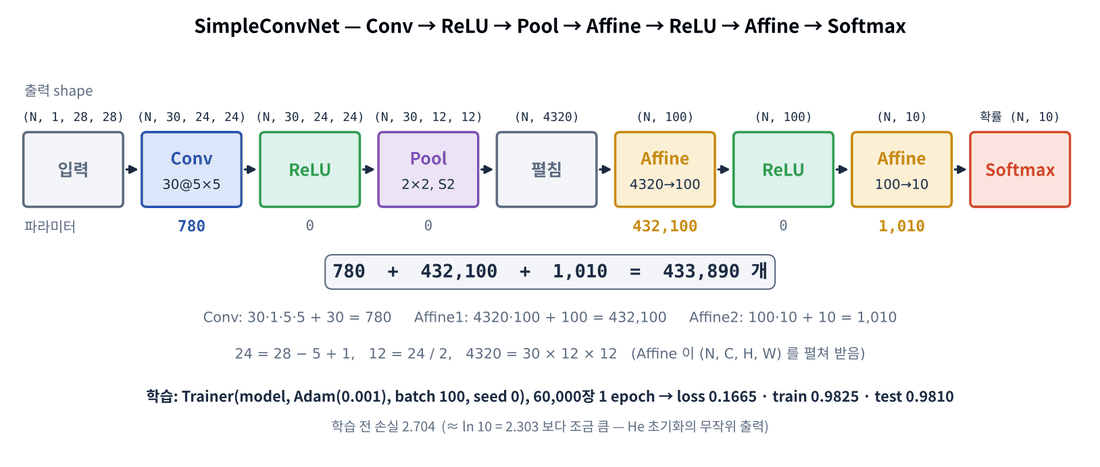

**Conv(1→30, 5×5) → ReLU → Pool(2×2) → Affine(4320→100) → ReLU → Affine(100→10) → Softmax**

Day 4 에서 Affine 을 (N, C, H, W) 입력도 받도록(내부에서 펼치도록) 만들어 두었으므로, Pooling 출력 (N, 30, 12, 12) 을 그대로 Affine 에 넣으면 됩니다.

**문제 5-1** 배치 100 일 때 단계별 출력 shape 를 예측하세요.

In [ ]:
shapes = {
    "input": (100, 1, 28, 28),
    "conv":  ____,       # (28 − 5)/1 + 1 = 24
    "pool":  ____,
    "fc1":   ____,
    "fc2":   (100, 10),
}

In [ ]:
#@title 🔒 정답 보기 5-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTEg4pSA4pSACnNoYXBlcyA9IHsKICAgICJpbnB1dCI6ICgxMDAsIDEsIDI4LCAyOCks"
    "CiAgICAiY29udiI6ICAoMTAwLCAzMCwgMjQsIDI0KSwgICAgICAgIyAoMjgg4oiSIDUpLzEgKyAxID0gMjQKICAg"
    "ICJwb29sIjogICgxMDAsIDMwLCAxMiwgMTIpLAogICAgImZjMSI6ICAgKDEwMCwgMTAwKSwKICAgICJmYzIiOiAg"
    "ICgxMDAsIDEwKSwKfQ=="
).decode("utf-8"))

**문제 5-2** `mynn` 으로 모델을 구성하세요. seed 는 1, 2, 3 (Affine1 의 입력 크기는 30·12·12).

In [ ]:
cnn = mynn.Sequential([
    ____,
    mynn.Relu(),
    ____,
    mynn.Affine(____, 100, seed=2),
    mynn.Relu(),
    mynn.Affine(100, 10, seed=3),
])

In [ ]:
h = X4_train[:100]
real = {"input": h.shape}
for name, layer in zip(["conv", None, "pool", "fc1", None, "fc2"], cnn.layers):
    h = layer.forward(h, train_flg=False)
    if name: real[name] = h.shape
for k in shapes:
    print(f"{'✅' if shapes[k] == real[k] else '❌'} {k:6s} 실제 {real[k]}  내 답 {shapes[k]}")
per_layer = {i: sum(p.size for p in L.params.values()) for i, L in enumerate(cnn.layers) if L.params}
print("계층별 파라미터", per_layer, "· 합계", f"{cnn.count_params():,}", "· 학습 전 손실", round(cnn.loss(X4_train[:100], t_train[:100]), 3))
assert shapes == real and cnn.count_params() == 433_890; print("✅")

In [ ]:
#@title 🔒 정답 보기 5-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTIg4pSA4pSACmNubiA9IG15bm4uU2VxdWVudGlhbChbCiAgICBteW5uLkNvbnZvbHV0"
    "aW9uKDEsIDMwLCA1LCBzdHJpZGU9MSwgcGFkPTAsIHNlZWQ9MSksCiAgICBteW5uLlJlbHUoKSwKICAgIG15bm4u"
    "UG9vbGluZygyLCAyLCBzdHJpZGU9MiksCiAgICBteW5uLkFmZmluZSgzMCAqIDEyICogMTIsIDEwMCwgc2VlZD0y"
    "KSwKICAgIG15bm4uUmVsdSgpLAogICAgbXlubi5BZmZpbmUoMTAwLCAxMCwgc2VlZD0zKSwKXSk="
).decode("utf-8"))

**문제 5-3** Day 4 와 같은 `Trainer` (Adam 0.001, 배치 100, seed 0) 로 **전체 6만 장 1 epoch** 학습하세요. test 를 validation 자리에 넣어 끝에 확인합니다. Colab CPU 에서 **2~4 분** 걸립니다 (그중 절반은 epoch 끝의 train 6만 장 정확도 평가).

In [ ]:
t0 = time.perf_counter()
trainer5 = mynn.Trainer(cnn, ____, batch_size=100, seed=0)
history5 = ____
print(f"학습 시간 {time.perf_counter() - t0:.0f} 초")
mynn.save_params(cnn, "day5_cnn.npz")

In [ ]:
plt.plot(np.convolve(history5["loss"], np.ones(20) / 20, mode="valid"))
plt.xlabel("iteration"); plt.ylabel("loss (smoothed)"); plt.title(f"CNN 1 epoch — test {history5['val_acc'][-1]:.4f}"); plt.grid(alpha=.3); plt.show()
assert history5["val_acc"][-1] >= 0.98; print("✅ CNN 1 epoch 이 Day 4 MLP 5 epoch (0.9757) 보다 높다")

In [ ]:
#@title 🔒 정답 보기 5-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTMg4pSA4pSACnQwID0gdGltZS5wZXJmX2NvdW50ZXIoKQp0cmFpbmVyNSA9IG15bm4u"
    "VHJhaW5lcihjbm4sIG15bm4uQWRhbShscj0wLjAwMSksIGJhdGNoX3NpemU9MTAwLCBzZWVkPTApCmhpc3Rvcnk1"
    "ID0gdHJhaW5lcjUuZml0KFg0X3RyYWluLCB0X3RyYWluLCBlcG9jaHM9MSwgWF92YWw9WDRfdGVzdCwgdF92YWw9"
    "dF90ZXN0KQpwcmludChmIu2VmeyKtSDsi5zqsIQge3RpbWUucGVyZl9jb3VudGVyKCkgLSB0MDouMGZ9IOy0iCIp"
    "Cm15bm4uc2F2ZV9wYXJhbXMoY25uLCAiZGF5NV9jbm4ubnB6Iik="
).decode("utf-8"))

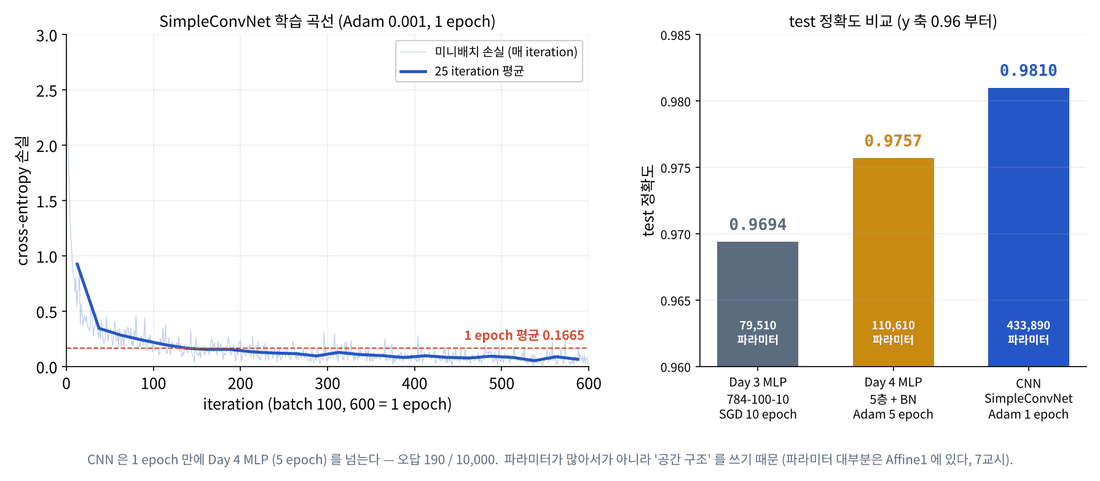

| | 모델 | 학습 | test |
|---|---|---|---|
| Day 3 | 784-100-10 MLP, SGD | 10 epoch | 0.9694 |
| Day 4 | 5층 MLP + BN + He, Adam | 5 epoch | 0.9757 |
| **Day 5** | **SimpleConvNet**, Adam | **1 epoch** | **0.9810** |

#### 📌 5교시 정리

- SimpleConvNet = Conv → ReLU → Pool → Affine → ReLU → Affine. 파라미터 433,890.
- Day 4 의 `Sequential` · `Trainer` 를 고치지 않고 계층만 추가해 CNN 을 학습 — 계층 규약의 힘.
- 1 epoch 만에 test 0.981 — 공간 구조를 쓰는 모델이 더 적은 학습으로 더 잘 맞힌다.

## 6교시 — 학습 결과 해석

CNN 이 무엇을 배웠는지 들여다봅니다. 1층 필터는 5×5 가중치 30장이라 **그림으로 그릴 수 있습니다**.

> 🎬 **애니메이션** [D5-7 필터 · 특징 맵](https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/animation.html#d5-7)  
> 📝 **워크시트** [6교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/worksheet.html#t6)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

**문제 6-1** 학습 전(같은 seed 로 새로 만든 계층)과 학습 후의 1층 필터 30장을 그리세요.

In [ ]:
W_before = mynn.Convolution(1, 30, 5, seed=1).params["W"]      # (30, 1, 5, 5) 무작위
W_after = ____
dW = W_after - W_before                                         # 1 epoch 동안 바뀐 양
fig, axs = plt.subplots(3, 30, figsize=(18, 2.4))
for i in range(30):
    for r, (Wf, cm) in enumerate([(W_before, "gray"), (W_after, "gray"), (dW, "RdBu_r")]):
        axs[r, i].imshow(Wf[i, 0], cmap=cm); axs[r, i].axis("off")
for r, name in enumerate(["before", "after", "after - before"]):
    axs[r, 0].set_title(name, fontsize=8, loc="left")
plt.show()
corr = [np.corrcoef(W_before[i].ravel(), W_after[i].ravel())[0, 1] for i in range(30)]
print(f"필터별 학습 전후 상관계수 {min(corr):.2f} ~ {max(corr):.3f},  변화량 크기 |ΔW|/|W0| = {np.linalg.norm(dW) / np.linalg.norm(W_before):.2f}")
assert W_after.shape == (30, 1, 5, 5) and not np.allclose(W_before, W_after); print("✅")

In [ ]:
#@title 🔒 정답 보기 6-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTEg4pSA4pSACldfYmVmb3JlID0gbXlubi5Db252b2x1dGlvbigxLCAzMCwgNSwgc2Vl"
    "ZD0xKS5wYXJhbXNbIlciXSAgICAgICMgKDMwLCAxLCA1LCA1KSDrrLTsnpHsnIQKV19hZnRlciA9IGNubi5sYXll"
    "cnNbMF0ucGFyYW1zWyJXIl0KZFcgPSBXX2FmdGVyIC0gV19iZWZvcmUgICAgICAgICAgICAgICAgICAgICAgICAg"
    "ICAgICAgICAgICAgICAgICMgMSBlcG9jaCDrj5nslYgg67CU64CQIOyWkQpmaWcsIGF4cyA9IHBsdC5zdWJwbG90"
    "cygzLCAzMCwgZmlnc2l6ZT0oMTgsIDIuNCkpCmZvciBpIGluIHJhbmdlKDMwKToKICAgIGZvciByLCAoV2YsIGNt"
    "KSBpbiBlbnVtZXJhdGUoWyhXX2JlZm9yZSwgImdyYXkiKSwgKFdfYWZ0ZXIsICJncmF5IiksIChkVywgIlJkQnVf"
    "ciIpXSk6CiAgICAgICAgYXhzW3IsIGldLmltc2hvdyhXZltpLCAwXSwgY21hcD1jbSk7IGF4c1tyLCBpXS5heGlz"
    "KCJvZmYiKQpmb3IgciwgbmFtZSBpbiBlbnVtZXJhdGUoWyJiZWZvcmUiLCAiYWZ0ZXIiLCAiYWZ0ZXIgLSBiZWZv"
    "cmUiXSk6CiAgICBheHNbciwgMF0uc2V0X3RpdGxlKG5hbWUsIGZvbnRzaXplPTgsIGxvYz0ibGVmdCIpCnBsdC5z"
    "aG93KCkKY29yciA9IFtucC5jb3JyY29lZihXX2JlZm9yZVtpXS5yYXZlbCgpLCBXX2FmdGVyW2ldLnJhdmVsKCkp"
    "WzAsIDFdIGZvciBpIGluIHJhbmdlKDMwKV0KcHJpbnQoZiLtlYTthLDrs4Qg7ZWZ7Iq1IOyghO2bhCDsg4HqtIDq"
    "s4TsiJgge21pbihjb3JyKTouMmZ9IH4ge21heChjb3JyKTouM2Z9LCAg67OA7ZmU65+JIO2BrOq4sCB8zpRXfC98"
    "VzB8ID0ge25wLmxpbmFsZy5ub3JtKGRXKSAvIG5wLmxpbmFsZy5ub3JtKFdfYmVmb3JlKTouMmZ9IikKYXNzZXJ0"
    "IFdfYWZ0ZXIuc2hhcGUgPT0gKDMwLCAxLCA1LCA1KSBhbmQgbm90IG5wLmFsbGNsb3NlKFdfYmVmb3JlLCBXX2Fm"
    "dGVyKTsgcHJpbnQoIuKchSIp"
).decode("utf-8"))

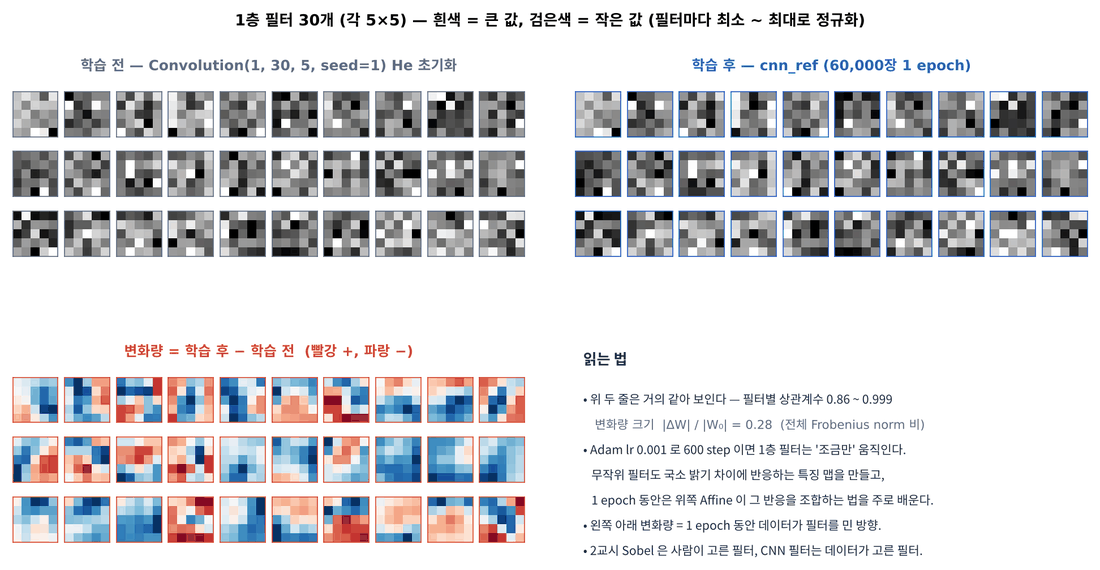

예상과 다를 수 있습니다 — 학습 전과 후가 **거의 같아 보입니다**. 필터별 상관계수가 0.86 ~ 0.999, 바뀐 양은 처음 크기의 약 28% 입니다. 1 epoch (Adam lr 0.001, 600 step) 동안 1층 필터는 **조금만** 움직였습니다.

- **무작위 필터도 쓸모가 있습니다.** 5×5 무작위 필터도 이웃 픽셀의 밝기 차이(국소 패턴)에 반응하는 특징 맵을 만들고, 1 epoch 동안 학습의 대부분은 뒤쪽 Affine 이 **그 반응들을 조합하는 법**을 배우는 데 쓰였습니다.
- **변화량(아래 줄)에는 방향이 있습니다.** 빨강 · 파랑이 한쪽으로 몰린 매끄러운 무늬 — 데이터가 필터를 경계 · 획 방향으로 **밀기 시작한** 흔적입니다. 더 오래 학습하거나 층이 깊어지면 2교시 Sobel 처럼 뚜렷한 에지 검출기가 나타납니다 (Vision 과정의 큰 모델에서 확인).
- 해석에서 중요한 습관: "그럴 것이다" 가 아니라 **그려 보고 숫자로 확인**합니다.

**문제 6-2** test 첫 숫자를 1층(Conv → ReLU)에 통과시킨 **특징 맵(feature map)** 30장을 그리세요.

In [ ]:
x1 = X4_test[:1]
fmap = ____     # Conv → ReLU
prob = mynn.softmax(cnn.predict(x1))[0]

In [ ]:
fig, axs = plt.subplots(3, 11, figsize=(14, 4))
axs[0, 0].imshow(x1[0, 0], cmap="gray_r"); axs[0, 0].set_title(f"input (t={t_test[0]})", fontsize=8)
for i in range(30):
    a = axs.ravel()[i + 1]; a.imshow(fmap[0, i], cmap="viridis"); a.set_title(f"#{i}", fontsize=7)
for a in axs.ravel(): a.axis("off")
axs.ravel()[-1].bar(range(10), prob); axs.ravel()[-1].axis("on"); axs.ravel()[-1].set_xticks(range(10))
plt.show()
assert fmap.shape == (1, 30, 24, 24) and prob.argmax() == t_test[0]; print("✅ 예측", prob.argmax(), f"(확률 {prob.max():.3f})")

In [ ]:
#@title 🔒 정답 보기 6-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTIg4pSA4pSACngxID0gWDRfdGVzdFs6MV0KZm1hcCA9IGNubi5sYXllcnNbMV0uZm9y"
    "d2FyZChjbm4ubGF5ZXJzWzBdLmZvcndhcmQoeDEsIEZhbHNlKSwgRmFsc2UpICAgICAjIENvbnYg4oaSIFJlTFUK"
    "cHJvYiA9IG15bm4uc29mdG1heChjbm4ucHJlZGljdCh4MSkpWzBd"
).decode("utf-8"))

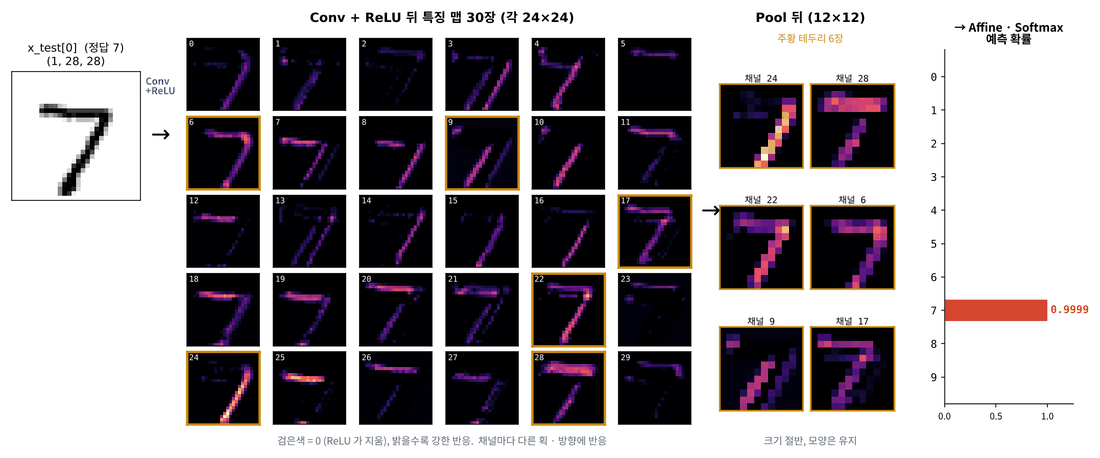

특징 맵마다 **밝게 반응하는 부분이 다릅니다** — 어떤 맵은 가로획, 어떤 맵은 오른쪽 경계, 어떤 맵은 배경. 뒤쪽 Affine 층은 이 30장의 "부품 검출 결과"를 조합해 숫자를 판단합니다. 층이 깊어지면 부품 → 모양 → 물체로 점점 추상적인 특징을 배웁니다 (Vision 과정의 깊은 CNN).

### MLP 와 비교 — 위치가 조금 바뀌면?

가중치 공유와 풀링 덕분에 CNN 은 **작은 이동**에 덜 민감할 것으로 기대됩니다. Day 4 의 5층 MLP (Drive 의 `day4_mlp.npz`, 없으면 여기서 다시 학습 — 약 30초) 와 비교합니다.

In [ ]:
def build_day4_mlp():
    sizes = [784, 100, 100, 100, 100, 10]; layers = []
    for i in range(5):
        layers.append(mynn.Affine(sizes[i], sizes[i + 1], seed=i + 1))
        if i < 4:
            layers += [mynn.BatchNorm(sizes[i + 1]), mynn.Relu()]
    return mynn.Sequential(layers)

mlp4 = build_day4_mlp()
if os.path.exists(f"{DRIVE_DIR}/day4_mlp.npz"):
    mynn.load_params(mlp4, f"{DRIVE_DIR}/day4_mlp.npz"); print("Drive 의 Day 4 MLP 를 불러왔습니다")
else:
    mynn.Trainer(mlp4, mynn.Adam(lr=0.001), batch_size=100, seed=0).fit(X_train, t_train, epochs=5, verbose=False)
    print("Day 4 MLP 를 다시 학습했습니다")
print(f"Day 4 MLP test {mlp4.accuracy(X_test, t_test):.4f}  ·  CNN test {cnn.accuracy(X4_test, t_test):.4f}")

**문제 6-3** test 이미지 전체를 오른쪽으로 0 ~ 3 픽셀 밀면서(`np.roll`, 너비 축) 두 모델의 정확도를 비교하세요.

In [ ]:
shift_acc = {"cnn": [], "mlp": []}
for s in range(4):
    xs = ____                      # (N, 1, 28, 28) 를 너비 방향으로
    shift_acc["cnn"].append(cnn.accuracy(xs, t_test))
    shift_acc["mlp"].append(____)

In [ ]:
for s in range(4):
    print(f"{s} px  CNN {shift_acc['cnn'][s]:.4f}   MLP {shift_acc['mlp'][s]:.4f}")
plt.plot(range(4), shift_acc["cnn"], "o-", label="CNN"); plt.plot(range(4), shift_acc["mlp"], "s--", label="MLP (Day 4)")
plt.xlabel("shift (px)"); plt.ylabel("test accuracy"); plt.legend(); plt.grid(alpha=.3); plt.show()
assert all(c > m for c, m in zip(shift_acc["cnn"][1:], shift_acc["mlp"][1:])); print("✅ 이동할수록 CNN 이 덜 떨어진다")

In [ ]:
#@title 🔒 정답 보기 6-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTMg4pSA4pSACnNoaWZ0X2FjYyA9IHsiY25uIjogW10sICJtbHAiOiBbXX0KZm9yIHMg"
    "aW4gcmFuZ2UoNCk6CiAgICB4cyA9IG5wLnJvbGwoWDRfdGVzdCwgcywgYXhpcz0zKSAgICAgICAgICAgICAgICAg"
    "ICAgICAjIChOLCAxLCAyOCwgMjgpIOulvCDrhIjruYQg67Cp7Zal7Jy866GcCiAgICBzaGlmdF9hY2NbImNubiJd"
    "LmFwcGVuZChjbm4uYWNjdXJhY3koeHMsIHRfdGVzdCkpCiAgICBzaGlmdF9hY2NbIm1scCJdLmFwcGVuZChtbHA0"
    "LmFjY3VyYWN5KHhzLnJlc2hhcGUoLTEsIDc4NCksIHRfdGVzdCkp"
).decode("utf-8"))

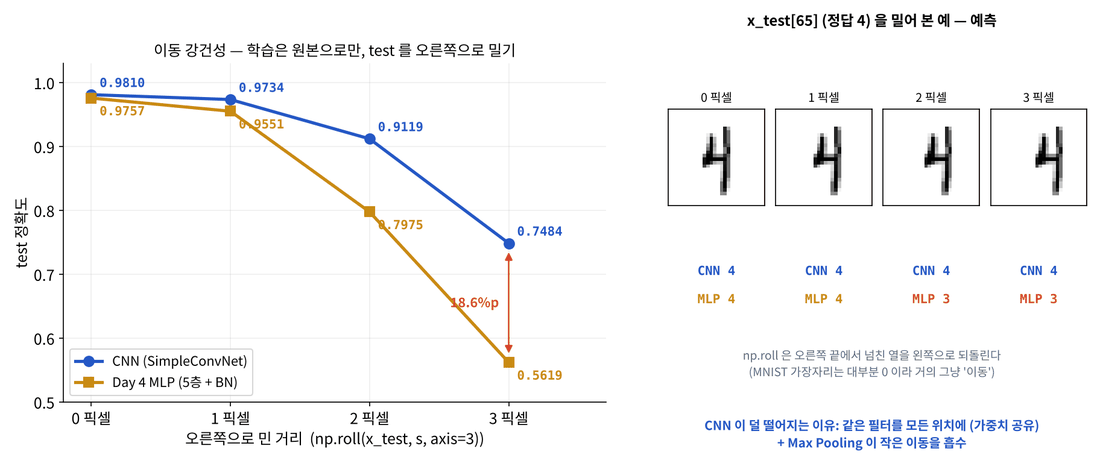

| | 파라미터 | 학습 | test | 2 px 이동 |
|---|---|---|---|---|
| Day 4 MLP | 110,610 | 5 epoch | 0.9757 | 0.7975 |
| CNN | 433,890 | 1 epoch | 0.9810 | **0.9119** |

CNN 도 3 px 이동에는 크게 떨어집니다 (0.748) — 풀링이 한 번(2×2)뿐이라 이동 둔감성이 제한적입니다. 실제 모델은 풀링을 여러 번 쓰고, 학습 때 이미지를 일부러 옮기고 돌리는 **데이터 증강(augmentation)** 으로 보완합니다 (Vision 과정).

#### 📌 6교시 정리

- 1 epoch 후 1층 필터는 초기값에서 조금만 바뀜 (상관 0.86~0.999) — 변화량에는 경계 방향 무늬. 특징 맵 = 필터마다 반응한 위치.
- CNN 은 더 적은 epoch 으로 더 높은 정확도, 작은 이동에 더 강함.
- 하지만 파라미터는 MLP 보다 많다 (433,890) — 어디에 몰려 있는지 7교시에서 계산.

## 7교시 — 모델 비용 계산

온디바이스 AI 에서 모델은 정확도만으로 고르지 않습니다. **메모리**(파라미터 · 활성화)와 **연산량**(시간 · 전력)을 계산할 수 있어야 합니다.

> 🎬 **애니메이션** [D5-8 모델 비용 계산기](https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/animation.html#d5-8)  
> 📝 **워크시트** [7교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/NN-day5/worksheet.html#t7)  
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

| 지표 | Convolution | Affine | 의미 |
|---|---|---|---|
| 파라미터 | $FN \cdot C \cdot FH \cdot FW + FN$ | $n_{in} \cdot n_{out} + n_{out}$ | 저장 공간 (float32 → ×4 바이트) |
| **MAC** (곱셈-덧셈) | $FN \cdot OH \cdot OW \cdot C \cdot FH \cdot FW$ | $n_{in} \cdot n_{out}$ | 연산 시간 · 전력 (이미지 **한 장** 기준) |
| 활성화 | $FN \cdot OH \cdot OW$ | $n_{out}$ | 실행 중 메모리 |

MAC (multiply-accumulate) 은 "곱하고 더하기" 한 번 — 출력 값 하나마다 필터 크기만큼 MAC 이 필요합니다. 합성곱은 가중치를 **공유**하므로 파라미터는 적지만, 같은 가중치를 **모든 위치에서 다시** 쓰므로 MAC 은 많습니다.

**문제 7-1 · 7-2** 비용 함수를 만드세요. 반환값은 (파라미터, MAC, 출력 shape) 입니다.

In [ ]:
def conv_cost(in_shape, FN, F, S=1, P=0):
    C, H, W = in_shape
    OH, OW = conv_output_size(H, F, S, P), conv_output_size(W, F, S, P)
    params = ____
    macs = ____
    return params, macs, (FN, OH, OW)

def pool_cost(in_shape, P=2):
    C, H, W = in_shape
    return 0, 0, (C, H // P, W // P)

def affine_cost(in_shape, n_out):
    n_in = int(np.prod(in_shape))
    return ____, ____, (n_out,)

In [ ]:
#@title 🔒 정답 보기 7-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTEg4pSA4pSACmRlZiBjb252X2Nvc3QoaW5fc2hhcGUsIEZOLCBGLCBTPTEsIFA9MCk6"
    "CiAgICBDLCBILCBXID0gaW5fc2hhcGUKICAgIE9ILCBPVyA9IGNvbnZfb3V0cHV0X3NpemUoSCwgRiwgUywgUCks"
    "IGNvbnZfb3V0cHV0X3NpemUoVywgRiwgUywgUCkKICAgIHBhcmFtcyA9IEZOICogQyAqIEYgKiBGICsgRk4KICAg"
    "IG1hY3MgPSBGTiAqIE9IICogT1cgKiBDICogRiAqIEYKICAgIHJldHVybiBwYXJhbXMsIG1hY3MsIChGTiwgT0gs"
    "IE9XKQoKZGVmIHBvb2xfY29zdChpbl9zaGFwZSwgUD0yKToKICAgIEMsIEgsIFcgPSBpbl9zaGFwZQogICAgcmV0"
    "dXJuIDAsIDAsIChDLCBIIC8vIFAsIFcgLy8gUCkKCmRlZiBhZmZpbmVfY29zdChpbl9zaGFwZSwgbl9vdXQpOgog"
    "ICAgbl9pbiA9IGludChucC5wcm9kKGluX3NoYXBlKSkKICAgIHJldHVybiBuX2luICogbl9vdXQgKyBuX291dCwg"
    "bl9pbiAqIG5fb3V0LCAobl9vdXQsKQ=="
).decode("utf-8"))

**문제 7-3** SimpleConvNet 의 층별 비용표를 만드세요. 각 층의 출력 shape 가 다음 층의 입력 shape 입니다.

In [ ]:
def cost_table(input_shape, spec):
    """spec: [("conv", FN, F, S, P), ("pool", 2), ("affine", n_out), ...] — ReLU 는 비용 0 이라 생략"""
    shape, rows = input_shape, []
    for item in spec:
        kind = item[0]
        if kind == "conv":
            p, m, shape = conv_cost(shape, *item[1:])
        elif kind == "pool":
            p, m, shape = pool_cost(shape, *item[1:])
        else:
            p, m, shape = ____
        rows.append((kind, shape, p, m, int(np.prod(shape))))
    return rows

def show(rows, title):
    print(title); print(f"  {'layer':7s} {'out shape':>14s} {'params':>10s} {'MAC':>12s} {'activ':>9s}")
    for k, s, p, m, a in rows:
        print(f"  {k:7s} {str(s):>14s} {p:>10,} {m:>12,} {a:>9,}")
    P, M = sum(r[2] for r in rows), sum(r[3] for r in rows)
    print(f"  {'total':7s} {'':>14s} {P:>10,} {M:>12,}   float32 {P * 4 / 1e6:.2f} MB · int8 {P / 1e6:.2f} MB\n")
    return P, M

simple_spec = [("conv", 30, 5, 1, 0), ("pool", 2), ("affine", 100), ("affine", 10)]
P_simple, M_simple = show(cost_table((1, 28, 28), simple_spec), "SimpleConvNet")

In [ ]:
assert (P_simple, M_simple) == (433_890, 865_000) and P_simple == cnn.count_params()
print("✅ 파라미터의 99.6% 는 Affine1 (432,100) 에, MAC 의 절반은 Conv (432,000) 에")

In [ ]:
#@title 🔒 정답 보기 7-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTIg4pSA4pSACmRlZiBjb3N0X3RhYmxlKGlucHV0X3NoYXBlLCBzcGVjKToKICAgICIi"
    "InNwZWM6IFsoImNvbnYiLCBGTiwgRiwgUywgUCksICgicG9vbCIsIDIpLCAoImFmZmluZSIsIG5fb3V0KSwgLi4u"
    "XSDigJQgUmVMVSDripQg67mE7JqpIDAg7J206528IOyDneuetSIiIgogICAgc2hhcGUsIHJvd3MgPSBpbnB1dF9z"
    "aGFwZSwgW10KICAgIGZvciBpdGVtIGluIHNwZWM6CiAgICAgICAga2luZCA9IGl0ZW1bMF0KICAgICAgICBpZiBr"
    "aW5kID09ICJjb252IjoKICAgICAgICAgICAgcCwgbSwgc2hhcGUgPSBjb252X2Nvc3Qoc2hhcGUsICppdGVtWzE6"
    "XSkKICAgICAgICBlbGlmIGtpbmQgPT0gInBvb2wiOgogICAgICAgICAgICBwLCBtLCBzaGFwZSA9IHBvb2xfY29z"
    "dChzaGFwZSwgKml0ZW1bMTpdKQogICAgICAgIGVsc2U6CiAgICAgICAgICAgIHAsIG0sIHNoYXBlID0gYWZmaW5l"
    "X2Nvc3Qoc2hhcGUsIGl0ZW1bMV0pCiAgICAgICAgcm93cy5hcHBlbmQoKGtpbmQsIHNoYXBlLCBwLCBtLCBpbnQo"
    "bnAucHJvZChzaGFwZSkpKSkKICAgIHJldHVybiByb3dzCgpkZWYgc2hvdyhyb3dzLCB0aXRsZSk6CiAgICBwcmlu"
    "dCh0aXRsZSk7IHByaW50KGYiICB7J2xheWVyJzo3c30geydvdXQgc2hhcGUnOj4xNHN9IHsncGFyYW1zJzo+MTBz"
    "fSB7J01BQyc6PjEyc30geydhY3Rpdic6PjlzfSIpCiAgICBmb3IgaywgcywgcCwgbSwgYSBpbiByb3dzOgogICAg"
    "ICAgIHByaW50KGYiICB7azo3c30ge3N0cihzKTo+MTRzfSB7cDo+MTAsfSB7bTo+MTIsfSB7YTo+OSx9IikKICAg"
    "IFAsIE0gPSBzdW0oclsyXSBmb3IgciBpbiByb3dzKSwgc3VtKHJbM10gZm9yIHIgaW4gcm93cykKICAgIHByaW50"
    "KGYiICB7J3RvdGFsJzo3c30geycnOj4xNHN9IHtQOj4xMCx9IHtNOj4xMix9ICAgZmxvYXQzMiB7UCAqIDQgLyAx"
    "ZTY6LjJmfSBNQiDCtyBpbnQ4IHtQIC8gMWU2Oi4yZn0gTUJcbiIpCiAgICByZXR1cm4gUCwgTQoKc2ltcGxlX3Nw"
    "ZWMgPSBbKCJjb252IiwgMzAsIDUsIDEsIDApLCAoInBvb2wiLCAyKSwgKCJhZmZpbmUiLCAxMDApLCAoImFmZmlu"
    "ZSIsIDEwKV0KUF9zaW1wbGUsIE1fc2ltcGxlID0gc2hvdyhjb3N0X3RhYmxlKCgxLCAyOCwgMjgpLCBzaW1wbGVf"
    "c3BlYyksICJTaW1wbGVDb252TmV0Iik="
).decode("utf-8"))

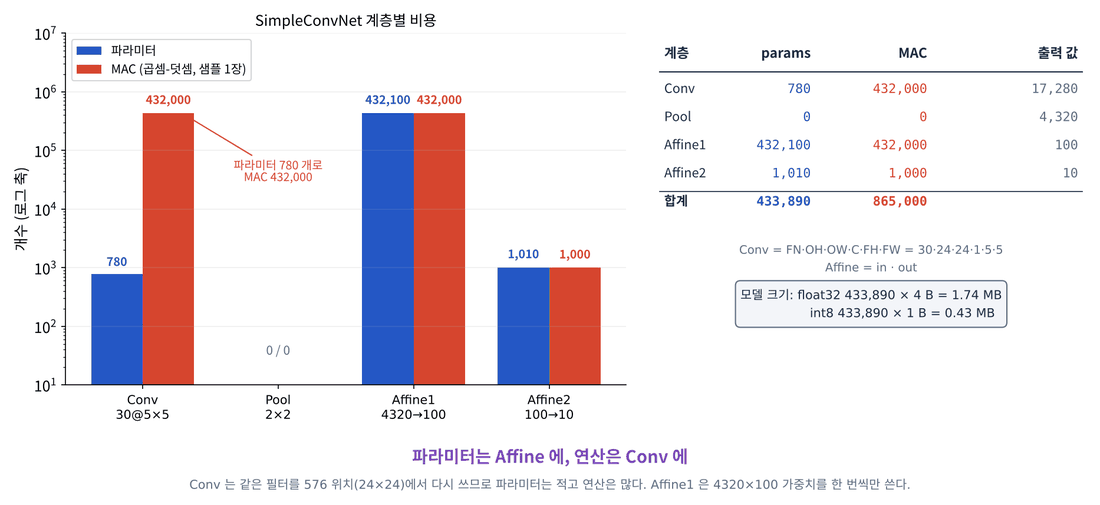

**"파라미터는 Affine 에, 연산은 Conv 에"** — SimpleConvNet 의 파라미터 433,890 개 중 432,100 개가 Pooling 출력 4,320 개를 100 개에 연결하는 Affine1 에 있습니다. 반대로 Conv 는 파라미터 780 개로 MAC 432,000 번을 씁니다.

### 경량 설계 — 줄일 곳이 보인다

Affine 에 들어가는 특징을 줄이면 파라미터가 급감합니다. 3×3 Conv 를 두 번 쓰고 풀링을 두 번 하면:

In [ ]:
lite_spec = [("conv", 16, 3, 1, 1), ("pool", 2), ("conv", 32, 3, 1, 1), ("pool", 2), ("affine", 10)]
P_lite, M_lite = show(cost_table((1, 28, 28), lite_spec), "경량 CNN")
big = conv_cost((3, 224, 224), 64, 3, 1, 1)
print(f"224×224×3 입력의 3×3×64 Conv 한 층: 파라미터 {big[0]:,} · MAC {big[1]:,} · 출력 {np.prod(big[2]):,} 값 = float32 {np.prod(big[2]) * 4 / 1e6:.1f} MB")
print(f"\n파라미터 {P_simple / P_lite:.0f} 배 감소, MAC 은 {M_lite / M_simple:.1f} 배")

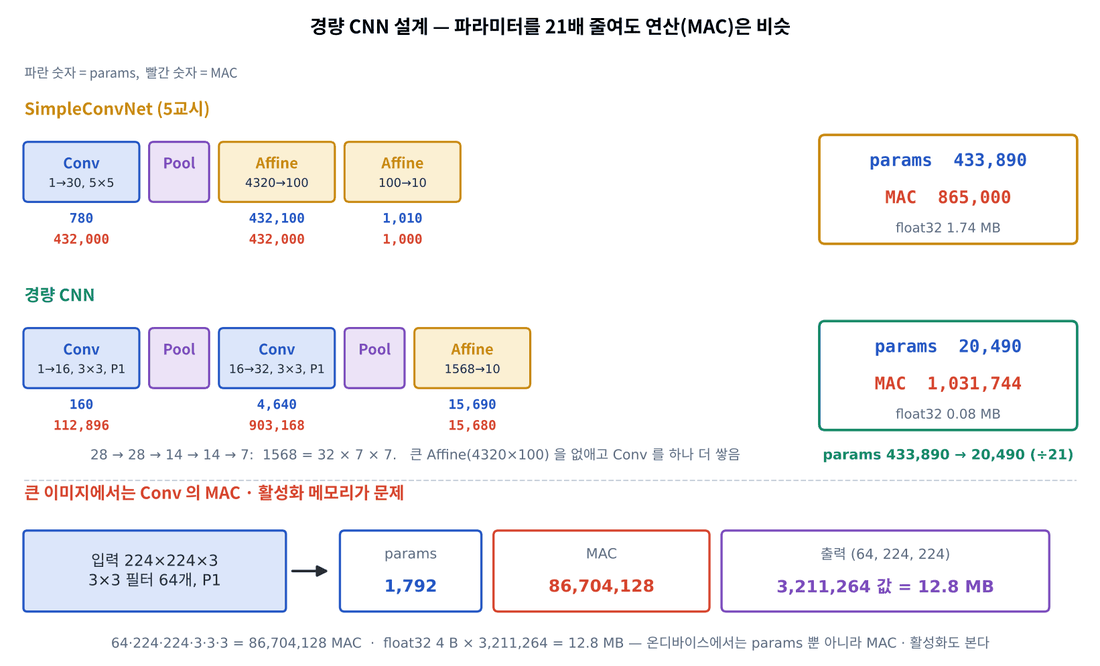

| | 파라미터 | MAC (1장) | float32 |
|---|---|---|---|
| SimpleConvNet | 433,890 | 865,000 | 1.74 MB |
| 경량 CNN | **20,490** (21배 ↓) | 1,031,744 | 0.08 MB |
| 224×224×3, 3×3×64 Conv **한 층** | 1,792 | **86,704,128** | 활성화 12.8 MB |

- 파라미터를 줄이면 **저장 공간**이 줄고, MAC 을 줄이면 **속도 · 전력**이 좋아집니다 — 둘은 다른 문제입니다.
- 큰 이미지에서는 파라미터보다 **MAC 과 활성화 메모리**가 병목입니다. 그래서 모바일용 모델(MobileNet 등)은 합성곱 자체를 가볍게 쪼개는 방법(depthwise separable conv)을 씁니다.
- Day 3 에서 본 **int8 양자화**는 메모리를 1/4 로 (float32 대비), Day 4 의 **BN folding** 은 계층 수를 줄입니다 — Vision 과정 이후 TensorRT · Quantization · Pruning 에서 본격적으로.

#### 📌 7교시 정리

- Conv: params $FN \cdot C \cdot F^2 + FN$, MAC $FN \cdot OH \cdot OW \cdot C \cdot F^2$. Affine: $n_{in} n_{out}$.
- SimpleConvNet: 433,890 params (대부분 Affine1), 865,000 MAC (절반이 Conv).
- 경량화: Affine 입력 줄이기(풀링 · 작은 필터), 양자화, 층 합치기.

## 8교시 — 평가 · 과정 정리

| 평가 | 비중 | 방법 |
|---|---|---|
| 일차별 미니 프로젝트 (Day 1~4) | 50% | 각 노트북의 채점 셀 |
| **필답 평가** | 30% | 강사가 공유하는 Google Forms 30문항 (객관식 · shape 계산 · 역전파 유도) — **17:00 ~ 17:25** |
| **CNN 실습 평가** | 20% | 아래 과제 1 ~ 4 + 채점 셀 — **17:25 ~ 17:50** |

### CNN 실습 평가

| 과제 | 내용 | 배점 |
|---|---|---|
| 1 | Convolution · Pooling gradient check (새 설정) | 30 |
| 2 | 학습한 CNN 저장 → 새 모델로 불러와 test ≥ 0.98 | 30 |
| 3 | 경량 CNN 비용표 직접 작성 | 30 |
| 4 | 결과 발표 정리 (마크다운) | 10 |

### 과제 1 — gradient check (30점)

입력 채널 2, 필터 3개, 4×4 필터, 스트라이드 2, 패딩 1 인 Convolution 과 3×3 Max Pooling (스트라이드 3) 을 `layer_check` 로 검사하세요. 입력은 `default_rng(5)` 의 정규분포 (2, 2, 9, 9).

In [ ]:
rng8 = np.random.default_rng(5)
x8 = rng8.normal(size=(2, 2, 9, 9))
eval_conv = ____
eval_pool = ____
print("conv", {k: f"{v:.1e}" for k, v in eval_conv.items()}, "\npool", {k: f"{v:.1e}" for k, v in eval_pool.items()})

In [ ]:
#@title 🔒 정답 보기 8-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTEg4pSA4pSACnJuZzggPSBucC5yYW5kb20uZGVmYXVsdF9ybmcoNSkKeDggPSBybmc4"
    "Lm5vcm1hbChzaXplPSgyLCAyLCA5LCA5KSkKZXZhbF9jb252ID0gbGF5ZXJfY2hlY2sobXlubi5Db252b2x1dGlv"
    "bigyLCAzLCA0LCBzdHJpZGU9MiwgcGFkPTEsIHNlZWQ9NyksIHg4LmNvcHkoKSwgcm5nOCkKZXZhbF9wb29sID0g"
    "bGF5ZXJfY2hlY2sobXlubi5Qb29saW5nKDMsIDMsIHN0cmlkZT0zKSwgeDguY29weSgpLCBybmc4KQpwcmludCgi"
    "Y29udiIsIHtrOiBmInt2Oi4xZX0iIGZvciBrLCB2IGluIGV2YWxfY29udi5pdGVtcygpfSwgIlxucG9vbCIsIHtr"
    "OiBmInt2Oi4xZX0iIGZvciBrLCB2IGluIGV2YWxfcG9vbC5pdGVtcygpfSk="
).decode("utf-8"))

### 과제 2 — 저장 · 불러오기 · 정확도 (30점)

5교시에 저장한 `day5_cnn.npz` 를 **다른 seed 로 새로 만든** SimpleConvNet 에 불러와 test 정확도를 확인하세요. 그리고 `mynn.py` 와 가중치를 Drive 에 복사합니다 (Vision 과정에서 다시 볼 수 있게).

In [ ]:
cnn2 = mynn.Sequential([mynn.Convolution(1, 30, 5, seed=11), mynn.Relu(), mynn.Pooling(2, 2, stride=2),
                        mynn.Affine(4320, 100, seed=12), mynn.Relu(), mynn.Affine(100, 10, seed=13)])
____
acc_cnn2 = ____
print(f"불러온 CNN test {acc_cnn2:.4f}")

if os.path.isdir("/content/drive/MyDrive"):
    os.makedirs(DRIVE_DIR, exist_ok=True)
    for f in ["mynn.py", "day5_cnn.npz"]:
        shutil.copy(f, DRIVE_DIR)
    print("Drive 에 저장:", sorted(os.listdir(DRIVE_DIR)))
else:
    print("Drive 가 연결되지 않아 복사를 건너뜁니다")

In [ ]:
#@title 🔒 정답 보기 8-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTIg4pSA4pSACmNubjIgPSBteW5uLlNlcXVlbnRpYWwoW215bm4uQ29udm9sdXRpb24o"
    "MSwgMzAsIDUsIHNlZWQ9MTEpLCBteW5uLlJlbHUoKSwgbXlubi5Qb29saW5nKDIsIDIsIHN0cmlkZT0yKSwKICAg"
    "ICAgICAgICAgICAgICAgICAgICAgbXlubi5BZmZpbmUoNDMyMCwgMTAwLCBzZWVkPTEyKSwgbXlubi5SZWx1KCks"
    "IG15bm4uQWZmaW5lKDEwMCwgMTAsIHNlZWQ9MTMpXSkKbXlubi5sb2FkX3BhcmFtcyhjbm4yLCAiZGF5NV9jbm4u"
    "bnB6IikKYWNjX2NubjIgPSBjbm4yLmFjY3VyYWN5KFg0X3Rlc3QsIHRfdGVzdCkKcHJpbnQoZiLrtojrn6zsmKgg"
    "Q05OIHRlc3Qge2FjY19jbm4yOi40Zn0iKQoKaWYgb3MucGF0aC5pc2RpcigiL2NvbnRlbnQvZHJpdmUvTXlEcml2"
    "ZSIpOgogICAgb3MubWFrZWRpcnMoRFJJVkVfRElSLCBleGlzdF9vaz1UcnVlKQogICAgZm9yIGYgaW4gWyJteW5u"
    "LnB5IiwgImRheTVfY25uLm5weiJdOgogICAgICAgIHNodXRpbC5jb3B5KGYsIERSSVZFX0RJUikKICAgIHByaW50"
    "KCJEcml2ZSDsl5Ag7KCA7J6lOiIsIHNvcnRlZChvcy5saXN0ZGlyKERSSVZFX0RJUikpKQplbHNlOgogICAgcHJp"
    "bnQoIkRyaXZlIOqwgCDsl7DqsrDrkJjsp4Ag7JWK7JWEIOuzteyCrOulvCDqsbTrhIjrnIHri4jri6QiKQ=="
).decode("utf-8"))

### 과제 3 — 경량 CNN 비용표 (30점)

다음 모델의 비용을 **`cost_table` 을 쓰지 말고** 층마다 `conv_cost` · `pool_cost` · `affine_cost` 를 직접 호출해 채우세요.

입력 (1, 28, 28) → Conv(8 필터, 3×3, S1, P1) → Pool 2 → Conv(16 필터, 3×3, S1, P1) → Pool 2 → Affine 10

In [ ]:
c1 = conv_cost((1, 28, 28), 8, 3, 1, 1)
p1 = pool_cost(c1[2])
c2 = ____
p2 = ____
a1 = ____
eval_params = ____
eval_macs = ____
print(f"출력 shape: {c1[2]} → {p1[2]} → {c2[2]} → {p2[2]} → {a1[2]}")
print(f"파라미터 {eval_params:,} · MAC {eval_macs:,} · float32 {eval_params * 4 / 1024:.1f} KB")

In [ ]:
#@title 🔒 정답 보기 8-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTMg4pSA4pSACmMxID0gY29udl9jb3N0KCgxLCAyOCwgMjgpLCA4LCAzLCAxLCAxKQpw"
    "MSA9IHBvb2xfY29zdChjMVsyXSkKYzIgPSBjb252X2Nvc3QocDFbMl0sIDE2LCAzLCAxLCAxKQpwMiA9IHBvb2xf"
    "Y29zdChjMlsyXSkKYTEgPSBhZmZpbmVfY29zdChwMlsyXSwgMTApCmV2YWxfcGFyYW1zID0gYzFbMF0gKyBjMlsw"
    "XSArIGExWzBdCmV2YWxfbWFjcyA9IGMxWzFdICsgYzJbMV0gKyBhMVsxXQpwcmludChmIuy2nOugpSBzaGFwZTog"
    "e2MxWzJdfSDihpIge3AxWzJdfSDihpIge2MyWzJdfSDihpIge3AyWzJdfSDihpIge2ExWzJdfSIpCnByaW50KGYi"
    "7YyM652866+47YSwIHtldmFsX3BhcmFtczosfSDCtyBNQUMge2V2YWxfbWFjczosfSDCtyBmbG9hdDMyIHtldmFs"
    "X3BhcmFtcyAqIDQgLyAxMDI0Oi4xZn0gS0IiKQ=="
).decode("utf-8"))

### 과제 4 — 결과 발표 정리 (10점, 강사 채점)

아래 셀에 3~5줄로 쓰고, 옆 사람에게 1분 동안 발표하세요.

1. 내 CNN 의 test 정확도와 Day 3 · 4 MLP 비교, 그 이유
2. 1층 필터 · 특징 맵에서 관찰한 것 한 가지
3. 이 CNN 을 스마트폰 / Jetson 에 올린다면 무엇을 줄이겠는가 (7교시 비용표 근거)

✍️ *여기에 정리를 쓰세요.*

In [ ]:
#@title 🔒 해설 보기 8교시 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIO2VtOyEpCDilIDilIAK7JiI7IucIOuLteyViDoKMS4gQ05OIOydgCAxIGVwb2NoIOyXkCB0ZXN0IDAu"
    "OTgxIOuhnCwgRGF5IDMgTUxQKDAuOTY5NCwgMTAgZXBvY2gpIMK3IERheSA0IE1MUCgwLjk3NTcsIDUgZXBvY2gp"
    "IOuztOuLpCDrhpLri6QuIO2VqeyEseqzseydtCDsnbTsm4Mg7ZS97IWAIOq0gOqzhCjsp4Dsl63shLEp66W8IOyT"
    "sOqzoCDqsJnsnYAg7ZWE7YSw66W8IOuqqOuToCDsnITsuZjsl5Ag6rO17Jyg7ZW0LCDsiKvsnpDsnZgg7ZqNIMK3"
    "IOqyveqzhCDqsJnsnYAg7Yq57KeV7J2EIOyggeydgCDrjbDsnbTthLDroZwg67Cw7Jqw6riwIOuVjOusuOydtOuL"
    "pC4g7ZS97IWA7J2EIOuSpOyEnuycvOuptCBNTFAg64qUIOygle2ZleuPhOqwgCDqsJnslZjripTrjbAsIENOTiDs"
    "nYAg6re4IOq1rOyhsOulvCDtmZzsmqntlZzri6QuCjIuIDEgZXBvY2gg7ZuEIDHsuLUg7ZWE7YSw64qUIOy0iOq4"
    "sOqwkuqzvCDqsbDsnZgg6rCZ7JWY7KeA66eMKOyDgeq0gCAwLjg2IOydtOyDgSkg67OA7ZmU65+J7JeQ64qUIOqy"
    "veqzhCDrsKntlqXsnZgg66ek64GE65+s7Jq0IOustOuKrOqwgCDsnojsl4jqs6AsIO2KueynlSDrp7Xrp4jri6Qg"
    "7Iir7J6Q7J2YIOyEnOuhnCDri6Trpbgg7ZqNKOqwgOuhnO2ajSwg7Jik66W47Kq9IOqyveqzhCDrk7Ep7JeQ7ISc"
    "IOqwle2VmOqyjCDrsJjsnZHtlojri6Qg4oCUIDEgZXBvY2gg64+Z7JWI7J2AIOyjvOuhnCDrkqTsqr0gQWZmaW5l"
    "IOydtCDtlZnsirXrkJjsl4jri6QuIDIgcHgg7J2064+Z7JeQ64+EIENOTiDsnYAgMC45MTIg66GcIE1MUCgwLjc5"
    "OCnrs7Tri6Qg642cIOuWqOyWtOyhjOuLpC4KMy4g7YyM652866+47YSw7J2YIDk5LjYlIOqwgCBBZmZpbmUxKDQz"
    "MjDihpIxMDAp7JeQIOyeiOycvOuvgOuhnCBDb252IMK3IFBvb2wg7J2EIO2VnCDrsogg642UIOuEo+yWtCBBZmZp"
    "bmUg7J6F66Cl7J2EIOykhOydtOqzoCjqsr3rn4kgQ05OIDIwLDQ5MCBwYXJhbXMpLCDqsIDspJHsuZjrpbwgaW50"
    "OCDroZwg7JaR7J6Q7ZmUKDEvNCntlZjrqbAsIO2BsCDsnoXroKXsl5DshJzripQgTUFDIOydtCDrs5HrqqnsnbTr"
    "r4DroZwg7ZWE7YSwIOyImCDCtyDtlbTsg4Hrj4Trpbwg7KSE7J2464ukLg=="
).decode("utf-8"))

### 채점 셀

In [ ]:
score = 0
try:
    assert all(v < 1e-7 for v in eval_conv.values()) and set(eval_conv) == {"dx", "W", "b"}
    assert all(v < 1e-7 for v in eval_pool.values())
    score += 30; print("✅ 과제 1  +30")
except Exception as e: print("❌ 과제 1", e)
try:
    assert acc_cnn2 >= 0.98 and abs(acc_cnn2 - cnn.accuracy(X4_test, t_test)) < 1e-12
    score += 30; print(f"✅ 과제 2  +30   (test {acc_cnn2:.4f})")
except Exception as e: print("❌ 과제 2", e)
try:
    assert c2[2] == (16, 14, 14) and p2[2] == (16, 7, 7) and a1[2] == (10,)
    assert eval_params == 80 + 1_168 + 7_850 and eval_macs == 56_448 + 225_792 + 7_840
    score += 30; print(f"✅ 과제 3  +30   ({eval_params:,} params · {eval_macs:,} MAC)")
except Exception as e: print("❌ 과제 3", e)
print(f"\n자동 채점 {score} / 90  (과제 4 는 강사 채점 10점)")

## 5일 과정 정리

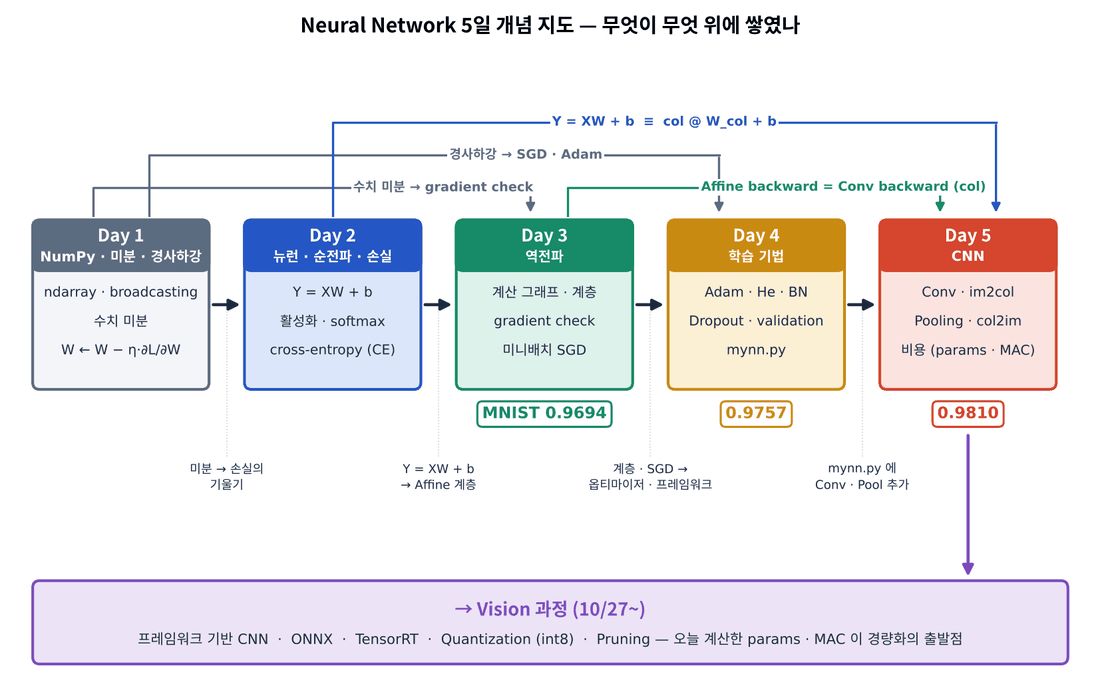

| 일차 | 핵심 | 직접 만든 것 | MNIST |
|---|---|---|---|
| Day 1 | NumPy · 미분 · 경사하강 | `numerical_gradient`, 경사하강 루프 | — |
| Day 2 | 뉴런 · 순전파 · 손실 ($Y = XW + b$, softmax, CE) | 퍼셉트론, `forward`, 로지스틱 회귀 | — |
| Day 3 | 역전파 (계산 그래프 · 계층 · gradient check · 미니배치 SGD) | `Affine`, `Relu`, `SoftmaxWithLoss`, `TwoLayerNet` | 0.9694 |
| Day 4 | 학습 기법 (Adam · He · BN · Dropout · validation) | 옵티마이저 5종, `BatchNorm`, **`mynn.py`** (`Sequential`, `Trainer`) | 0.9757 |
| Day 5 | CNN (합성곱 · im2col · 풀링 · 비용) | `im2col`, `Convolution`, `Pooling` → `mynn.py` | **0.9810** |

**한 줄 요약**: 신경망 = $XW + b$ 와 비선형 함수를 쌓은 것, 학습 = 손실의 기울기를 **역전파**로 구해 조금씩 내려가는 것, CNN = 같은 작은 필터를 이미지 전체에 **공유**하는 Affine.

### 셀프 체크 (Day 5)

- [ ] 완전연결층이 공간 정보를 쓰지 않는다는 것을 픽셀 뒤섞기 실험으로 설명할 수 있다
- [ ] $OH = (H + 2P - FH)/S + 1$ 과 (N, C, H, W) · (FN, C, FH, FW) · (N, FN, OH, OW) shape 를 쓸 수 있다
- [ ] im2col 로 합성곱을 행렬곱으로 바꾸는 원리와 속도 · 메모리 교환을 설명할 수 있다
- [ ] Convolution backward 가 Affine backward + col2im 이고, Max Pooling backward 가 argmax 로만 흐르는 것을 구현했다
- [ ] `mynn` 으로 SimpleConvNet 을 구성해 test 0.98 이상을 얻었다
- [ ] 학습 전후 필터 · 변화량 · 특징 맵을 그려 해석하고 MLP 와 이동 강건성을 비교했다
- [ ] Conv · Affine 의 파라미터 · MAC 을 계산하고 경량화 방향을 제시할 수 있다

### 다음 과정 — Vision 기본 모델 (10/27 ~)

이제 PyTorch 같은 프레임워크를 쓸 차례입니다. `nn.Conv2d`, `nn.BatchNorm2d`, `optim.Adam`, `loss.backward()` — 이름은 달라도 **여러분이 NumPy 로 직접 만든 것과 같은 일**을 합니다 (`loss.backward()` 는 오늘까지 만든 역전파, `optimizer.step()` 은 `update(params, grads)`). 그 위에서 더 깊은 CNN(VGG · ResNet · MobileNet), 데이터 증강, 전이 학습을 다루고, ONNX · TensorRT · Quantization · Pruning 으로 Jetson 에 올리는 경량화로 이어집니다. 7교시 비용표가 그 출발점입니다.

**5일 동안 수고하셨습니다.** Drive 의 `NN_course/` 폴더(`mynn.py`, `day4_mlp.npz`, `day5_cnn.npz`)는 여러분이 처음부터 만든 딥러닝 프레임워크입니다.